# NB\_C07: Neural Dynamics - The Hopf Model on the Connectome

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/arvidl/glioma-brain-digital-twin-public/blob/main/notebooks/NB_C07_Neural_Dynamics.ipynb)

**Capstone Notebook Series** -- Glioma Brain Digital Twin Project  
**Workshop:** Mathematical Challenges in Brain Mechanics ([CAS 2025/2026](https://cas-nor.no/project/mathematical-challenges-brain-mechanics)), 9-11 March 2026, Hotel Finse 1222 [[link](https://cas-nor.no/events/mathematical-challenges-brain-mechanics-workshop)]  
**Patient:** sub-PAT16 (anaplastic astrocytoma WHO II--III, fronto-temporal) from the OpenNeuro repository [[preop](https://openneuro.org/datasets/ds001226/versions/5.0.0)] [[postop](https://openneuro.org/datasets/ds002080/versions/4.0.0)]<br>
**Date:** 9 March 2026 <br>
**Creator:** Arvid Lundervold w/ Cursor 2.6.14 and GTP-5.4

---

## Objectives

- Understand neural mass models and the Hopf bifurcation
- Simulate neural dynamics on the patient-specific connectome
- Implement the mechanics-dynamics coupling (SC modulation + bifurcation shift)
- Compare simulated FC with empirical FC

**Prerequisites:** [NB\_C04](NB_C04_Diffusion_MRI_Tractography.ipynb), [NB\_C05](NB_C05_Resting_State_fMRI.ipynb), [NB\_C06](NB_C06_Brain_Mechanics.ipynb)  
**Next:** [NB\_C08](NB_C08_Closing_the_Loop.ipynb) (closing the loop)

## Neural dynamics - microscale, mesoscale, macroscale in glioma brain digital twin

This notebook works at the **macroscale**, but it helps to understand how that level relates to the smaller scales of brain function. In a glioma brain digital twin, the goal is not only to represent anatomy and mechanics, but also to capture how tumour-related changes can propagate into **neural activity**, **functional connectivity**, and ultimately **brain state**.

### The big picture

Neural dynamics can be described at three complementary scales:

| Scale | What is modeled? | Typical variables | Typical models | Why it matters for glioma |
|---|---|---|---|---|
| **Microscale** | Single cells and synapses | Membrane voltage, ion channels, spikes | Hodgkin-Huxley, integrate-and-fire | Explains how tumour infiltration, edema, inflammation, or altered neurotransmission may change excitability locally |
| **Mesoscale** | Local populations of neurons | Mean firing rate, excitation/inhibition balance, local field activity | Wilson-Cowan, Jansen-Rit, neural mass models | Captures how local circuits become hyperexcitable, suppressed, or dysregulated near the lesion |
| **Macroscale** | Whole brain regions connected by white-matter tracts | Regional amplitudes, phases, inter-regional coupling | Hopf whole-brain models, mean-field connectome models | Lets us study how structural disruption reshapes large-scale functional networks |

### 1. Microscale: the level of cells and synapses

At the microscale, we ask questions such as:

- How does a neuron generate an action potential?
- How do synapses excite or inhibit neighboring neurons?
- How do altered ion concentrations or metabolic stress affect firing?

This scale is the most biologically detailed. It is also the most computationally expensive. A patient-specific whole-brain simulation with explicit neurons would require modeling enormous numbers of cells and synapses, which is far beyond the scope of a practical clinical digital twin.

For glioma, microscale mechanisms still matter conceptually because the tumour microenvironment can modify:

- **Excitability** of nearby neurons
- **Excitation-inhibition (E/I) balance**
- **Synaptic efficacy** and local communication
- **Noise and heterogeneity** in neural responses

These cellular effects motivate the larger-scale parameters we use later, even if we do not model every neuron explicitly.

### 2. Mesoscale: the level of local circuits and populations

At the mesoscale, we no longer track individual spikes. Instead, we summarize the collective behavior of many neurons in a cortical column or local population. This is often a better match to measurements such as:

- local field potentials,
- EEG rhythms,
- aggregate firing rate,
- and local oscillatory activity.

Here, the key idea is that a local circuit can often be described by a small set of effective variables, for example:

- mean excitatory activity,
- mean inhibitory activity,
- or an oscillation amplitude and phase.

This is where **neural mass models** become useful. They compress many microscopic interactions into a lower-dimensional dynamical system that still captures meaningful phenomena such as:

- oscillations,
- damped responses,
- multistability,
- and transitions between quiescent and active states.

In glioma, the mesoscale is especially important because tissue close to the tumour may shift into a different dynamical regime: more excitable, less stable, or more weakly connected.

### 3. Macroscale: the level of brain regions and networks

At the macroscale, each node represents an entire brain region rather than a single neuron or a local microcircuit. The regions are connected by the patient-specific **structural connectivity (SC)** matrix derived from diffusion MRI tractography. Neural activity evolves over this network and gives rise to simulated **functional connectivity (FC)**.

This is the scale used in this notebook.

Why is macroscale modeling attractive for a digital twin?

- It is computationally tractable.
- It can be personalized using the patient's connectome.
- It links structure to function.
- It can incorporate biomechanical perturbations from the tumour and mass effect.
- It is suitable for testing hypotheses about pre-operative and post-operative network changes.

### How the scales connect

These three scales should not be thought of as competing descriptions. They are different views of the same system.

A useful way to think about them is:

- **Microscale** explains the mechanisms.
- **Mesoscale** explains the local circuit phenotype.
- **Macroscale** explains the distributed network consequences.

In a glioma brain digital twin, the workflow is often:

1. **Tumour growth and mechanics** alter tissue geometry, deformation, and local environment.
2. These changes are interpreted as perturbations to neural parameters such as coupling strength or excitability.
3. A whole-brain neural model propagates those local perturbations through the connectome.
4. The resulting dynamics are compared with measured functional data.

### Where the Hopf model fits

The **Hopf model** is a macroscale neural mass model for each brain region. It is especially useful because it captures a fundamental idea: a region may sit near a **bifurcation**, where a small parameter change can move it from noisy, weak activity into sustained oscillatory activity.

That makes it a natural model for glioma-related perturbations.

In this notebook, two effects from the digital twin are especially important:

- **Structural modulation:** mechanical and tumour-related changes may weaken or reshape effective coupling between regions.
- **Bifurcation shift:** local tissue perturbation may move a region closer to or farther from the oscillatory regime by changing its effective control parameter.

This gives a compact but interpretable bridge between biomechanics and brain dynamics.

### Intuition to keep in mind

A practical mental model for the rest of the notebook is:

- the **connectome** provides the wiring,
- the **Hopf dynamics** provide the regional activity rule,
- the **glioma and mass effect** perturb the wiring and the operating point,
- and the resulting whole-brain activity generates a predicted FC pattern.

So although we simulate only the macroscale directly, the model is informed by smaller-scale biology and is designed to test system-level consequences of local pathology.

### Take-home message

For a glioma brain digital twin, neural dynamics are most useful when viewed as a multiscale problem:

- **Microscale:** what happens to cells and synapses near the tumour?
- **Mesoscale:** how do local circuits become dysregulated?
- **Macroscale:** how do these local changes reorganize whole-brain networks?

This notebook focuses on the last question, using the Hopf model on a patient-specific connectome as a mathematically simple but biologically meaningful model of whole-brain neural dynamics.

## How this works in the present PAT16 data

The previous cell introduced the multiscale idea. Here is how that abstract picture becomes a **patient-specific neural dynamics model** for **sub-PAT16**, a patient with a **fronto-temporal glioma**.

The key modeling move is simple:

- we reduce the cortex to **68 anatomically defined regions**,
- estimate how strongly these regions are **structurally connected**,
- estimate how strongly their resting-state BOLD signals are **functionally correlated**,
- and then ask whether a whole-brain dynamical model can reproduce the observed functional pattern from the structural scaffold.

### PAT16 digital twin: modality-to-model map

```text
PAT16 anatomy + diffusion MRI + resting-state fMRI + biomechanics
                |
                v
1. T1w MRI + FreeSurfer -> DK68 cortical parcellation (68 nodes)
                |
                +--> diffusion MRI + tractography + SIFT2
                |         -> structural connectivity SC (68 x 68)
                |
                +--> resting-state fMRI
                |         -> one BOLD time course per DK68 region
                |         -> empirical functional connectivity FC (68 x 68)
                |
                +--> tumour / mass-effect mechanics model
                          -> regional perturbation map
                          -> SC modulation + Hopf bifurcation shift
                |
                v
2. Hopf dynamics on the patient-specific connectome
                |
                v
3. Simulated FC compared with empirical rsFC
```

### 1. Structural side: what are the nodes and edges?

#### Nodes: the DK68 parcellation

For PAT16, the cortex is represented using the **Desikan-Killiany atlas** with **68 cortical parcels**: 34 in the left hemisphere and 34 in the right hemisphere. In the digital twin, each parcel is treated as one network node.

This is a deliberate modeling compromise:

- it is **fine-grained enough** to separate frontal, temporal, parietal, and occipital systems,
- but still **coarse enough** to make whole-brain simulation tractable,
- and it gives a common node definition across structural MRI, diffusion MRI, and fMRI.

In other words, the parcellation is the bridge that lets different modalities talk to each other.

#### Edges: structural connectivity from diffusion MRI tractography

The structural connectivity matrix for PAT16 is derived from diffusion MRI using:

- anatomically constrained tractography (ACT),
- probabilistic streamline tracking,
- and **SIFT2** weighting.

For a pair of parcels $i$ and $j$, the structural edge weight is interpreted as the **sum of SIFT2-weighted streamlines** connecting those two regions:

$$
\mathrm{SC}_{ij} = \sum_{s \in \mathcal{S}_{ij}} \mu_s
$$

where $\mathcal{S}_{ij}$ is the set of streamlines whose endpoints are assigned to parcels $i$ and $j$, and $\mu_s$ is the SIFT2 weight for streamline $s$.

This is important didactically: the structural edge weight is **not** a direct count of axons and **not** a synaptic strength. It is a tractography-based estimate of **macroscopic connection capacity**.

For PAT16 in this project:

- the pre-op SC loaded in the notebook has shape **68 x 68**,
- it is treated as a **weighted, symmetric** region-to-region matrix,
- and its reported density is about **0.475**, meaning the connectome is neither fully dense nor extremely sparse.

#### Structural assumptions to keep in mind

1. Each DK68 parcel is assumed to be internally homogeneous enough to be represented by a single node.
2. Streamline-derived connectivity is assumed to be a useful proxy for large-scale anatomical coupling.
3. Symmetrising and thresholding the matrix is assumed to reduce tractography noise and false positives.
4. The main lesion-related structural effects are expected to appear as altered coupling in and around the **ipsilesional fronto-temporal network neighborhood**.

### 2. Functional side: how do we get rsFC from PAT16 fMRI?

The empirical FC matrix is built from the PAT16 **resting-state fMRI** data after preprocessing. Conceptually, the procedure is:

1. Start with the preprocessed BOLD image sequence.
2. Use the same DK68 atlas to identify which voxels belong to each cortical region.
3. Average the BOLD signal across voxels within each region to obtain one regional time course per parcel.
4. Compute pairwise statistical dependence between regional time courses.

If $x_i(t)$ denotes the regional BOLD time course for parcel $i$, then the regional signal is:

$$
x_i(t) = \frac{1}{|R_i|} \sum_{v \in R_i} y_v(t)
$$

where $R_i$ is the set of voxels in region $i$ and $y_v(t)$ is the BOLD signal at voxel $v$ and time $t$.

The empirical FC edge between regions $i$ and $j$ is then computed here as the **Pearson correlation** between the two regional BOLD time series:

$$
\mathrm{FC}_{ij} = \mathrm{corr}(x_i, x_j)
$$

This gives a symmetric matrix whose entries range from negative to strongly positive values.

For PAT16 in this project:

- the pre-op empirical FC matrix also has shape **68 x 68**,
- the reported range is approximately **[-0.392, 0.956]**,
- so the data contain both anti-correlated and strongly positively correlated regional pairs.

#### Functional assumptions to keep in mind

1. The mean BOLD signal within a DK68 parcel is assumed to be a reasonable summary of that region's activity.
2. Pearson correlation is assumed to capture the dominant resting-state statistical relationship between two regions.
3. The observed rsFC is treated as a systems-level fingerprint of ongoing neural interactions, even though BOLD is an indirect hemodynamic readout.
4. In glioma, neurovascular coupling may be altered near the lesion, so FC should be interpreted with caution: some changes may reflect altered hemodynamics as well as altered neural activity.

### 3. Why these assumptions are scientifically reasonable

These assumptions are not arbitrary shortcuts. They reflect standard practice in whole-brain connectomics and neural mass modeling.

#### Why the DK68 atlas is reasonable here

- It is a widely used anatomical atlas.
- It is stable and reproducible across subjects.
- It aligns naturally with FreeSurfer outputs already used elsewhere in the project.
- It gives enough anatomical specificity to discuss a **fronto-temporal glioma** without exploding the model dimensionality.

#### Why SIFT2-weighted tractography is reasonable here

- Raw streamline count is biased by tractography seeding density and geometry.
- SIFT2 improves biological plausibility by fitting streamline weights to the diffusion-derived fiber density.
- It therefore gives a better whole-brain coupling scaffold for downstream dynamical modeling than naive streamline counting.

#### Why Pearson rsFC is reasonable here

- It is the standard baseline measure in resting-state connectomics.
- It is simple, interpretable, and robust enough for patient-specific exploratory modeling.
- It provides a direct target for the Hopf model, which is designed to reproduce correlation structure from the structural network.

### 4. What the PAT16 data are really saying

A useful interpretation framework is:

| Data object | What it encodes | What it does **not** directly encode |
|---|---|---|
| **SC matrix** | Estimated macroscopic anatomical coupling between DK68 regions | Exact axon counts, synaptic efficacy, causal influence |
| **FC matrix** | Similarity of spontaneous BOLD fluctuations between regions | Direct anatomical wiring, directionality, pure neural causality |
| **FEM displacement field** | Mechanical deformation and mass effect due to tumour / tissue changes | Neural activity by itself |
| **Hopf parameters** | Effective operating point and coupling in the dynamical model | Full microscopic cellular detail |

This distinction matters. The digital twin does **not** claim that correlation equals causation, or that tractography equals true wiring in a microscopic sense. Instead, it asks a sharper and more realistic question:

> Given the measured anatomy, connectome, rs-fMRI, and mechanics for PAT16, can a parsimonious dynamical model explain the large-scale functional organization of this patient's brain?

### 5. Why the glioma matters dynamically in PAT16

PAT16 is not just any connectomics subject. The patient has a **fronto-temporal glioma**, which makes at least three mechanisms relevant:

1. **Local tissue disruption.**  Tumour infiltration, edema, and altered microenvironment can change local excitability and E/I balance.
2. **White-matter pathway perturbation.**  Compression, invasion, or reorganization can weaken or reroute effective structural coupling.
3. **Hemodynamic distortion.**  The BOLD signal may become less faithful to underlying neural activity near the lesion because neurovascular coupling can be altered in tumour tissue or peritumoral tissue.

This is exactly why a mechanics-aware neural dynamics model is interesting: it allows us to test whether lesion-induced physical perturbations can help explain altered network function.

### 6. Evidence-based interpretations for this notebook

The most defensible interpretations are the following.

#### Interpretation A: the model is strongly patient-specific

This notebook is not running a generic healthy-brain connectome. It loads **PAT16-specific** SC, FC, and FEM-derived displacement information. That means the simulation is anchored in this patient's measured anatomy, connectivity, and lesion-related deformation.

#### Interpretation B: the whole-brain problem is a structure-to-function problem

The central scientific question is whether the observed PAT16 rsFC can be reproduced from:

- the patient-specific structural scaffold,
- a low-dimensional regional dynamics model,
- and lesion-related perturbations to coupling and excitability.

This makes the notebook an explicit test of the hypothesis that **large-scale functional organization emerges from anatomy plus dynamics**, rather than from FC alone.

#### Interpretation C: deviations between simulated FC and empirical FC are informative

A mismatch is not merely a failure. It can indicate that the model is missing one or more relevant mechanisms, for example:

- region-specific heterogeneity beyond a uniform parameter set,
- delayed coupling or frequency-specific effects,
- altered neurovascular coupling near the tumour,
- or post-lesional compensatory reorganization that is not captured by simple SC modulation.

#### Interpretation D: fronto-temporal lesion effects should be local in origin but distributed in consequence

Because the tumour is fronto-temporal, the most immediate perturbations are expected near **ipsilesional frontal and temporal parcels** and the tracts that connect them. But the consequences need not stay local. Through the connectome, local perturbations can propagate into distant systems and change the global FC pattern.

That local-to-global propagation is precisely what whole-brain neural dynamics is designed to capture.

### 7. Mental picture for the rest of the notebook

A good way to read the upcoming analyses is this:

```text
DK68 parcels define where the nodes are.
Diffusion MRI tells us how the nodes are wired.
Resting-state fMRI tells us which nodes fluctuate together.
Biomechanics tells us where the tumour perturbs tissue and connectivity.
Hopf dynamics tells us how these ingredients may generate the observed FC.
```

### Take-home message

In PAT16, the digital twin turns multimodal patient data into a unified network model:

- **DK68 parcellation** gives the nodes,
- **SIFT2-weighted tractography** gives the structural edges,
- **regional BOLD averaging + Pearson correlation** gives the empirical functional edges,
- and **mechanics-aware Hopf dynamics** provides the bridge from lesion-induced perturbation to whole-brain function.

The power of the approach is not that any single matrix is the truth. The power is that **multiple imperfect but complementary measurements are integrated into one testable dynamical hypothesis about this patient's brain**.

## Figure-style summary: SC vs FC vs Hopf parameters vs mechanics

The digital twin combines four complementary objects. They answer different questions, live at different levels of description, and should not be interpreted as interchangeable.

| Object | In this notebook, it means | Derived from | Mathematical role | Main interpretation | Main caveat |
|---|---|---|---|---|---|
| **SC** | Structural connectivity between DK68 regions | Diffusion MRI tractography + ACT + SIFT2 | Network coupling scaffold $\mathrm{SC}_{ij}$ | Which regions are anatomically linked strongly enough to exchange activity efficiently | Tractography is indirect and can miss or overestimate pathways |
| **FC** | Resting-state functional connectivity between DK68 regional BOLD signals | rs-fMRI regional time courses + Pearson correlation | Empirical target matrix $\mathrm{FC}_{ij}$ | Which regions fluctuate together during rest | Correlation is not directionality or causality; BOLD is indirect |
| **Hopf parameters** | Effective local operating point and global coupling of the neural model | Model assumptions fitted/explored against PAT16 data | Governs oscillatory regime, noise sensitivity, and coupling-driven coordination | How close each region is to a transition between noisy and oscillatory dynamics | Parameters are effective descriptions, not direct biological measurements |
| **Mechanics** | Tumour-related deformation and mass effect | FEM displacement field from the mechanics pipeline | Perturbs SC and/or shifts the Hopf bifurcation parameter | How tissue displacement may alter connectivity and excitability | Mechanical deformation is not itself neural activity |

### One-line intuition

- **SC** says how the brain is wired.
- **FC** says which regions co-fluctuate.
- **Hopf parameters** say how each region tends to behave dynamically.
- **Mechanics** says how the glioma perturbs the substrate on which dynamics unfold.

### Compact PAT16 pipeline

```text
PAT16 diffusion MRI -> SC
PAT16 resting-state fMRI -> FC
PAT16 tumour biomechanics -> perturbation map
SC + Hopf dynamics + mechanics -> simulated FC
simulated FC vs empirical FC -> model validation / interpretation
```

### Why all four are needed

If we used only **SC**, we would know the anatomical scaffold but not the observed functional organization.
If we used only **FC**, we would know the correlations but not the structural or mechanistic constraints behind them.
If we used only **Hopf dynamics**, we would have a generic model without patient specificity.
If we used only **mechanics**, we would know where tissue is deformed but not how that deformation affects network function.

The digital twin becomes interesting only when these are combined into one coherent hypothesis:

> in PAT16, glioma-related mechanical perturbation alters the structural and dynamical substrate, and those changes help shape the resting-state functional connectivity observed in the patient.

In [1]:
# PAT16 intro figures: load SC, FC, regional BOLD, and mechanics in a self-contained way.
# These cells are placed early in the notebook so they re-import what they need.

import json
from pathlib import Path

import nibabel as nib
import numpy as np
import matplotlib.pyplot as plt
from scipy import ndimage as ndi
from scipy.io import loadmat
from scipy.stats import pearsonr, spearmanr

REPO_ROOT = Path.cwd().resolve()
if not (REPO_ROOT / 'pyproject.toml').exists():
    REPO_ROOT = REPO_ROOT.parent

TVB_DIR = REPO_ROOT / 'data' / 'BIDS_preop_postop' / 'derivatives' / 'TVB' / 'sub-PAT16' / 'ses-preop'
CONN_DIR = REPO_ROOT / 'derivatives' / 'connectivity' / 'sub-PAT16' / 'ses-preop'
LONG_DIR = REPO_ROOT / 'derivatives' / 'registered_t1w' / 'sub-PAT16' / 'longitudinal'
POSTOP_ANAT_DIR = REPO_ROOT / 'derivatives' / 'fmriprep' / 'sub-PAT16' / 'ses-postop' / 'anat'
FIG_DIR = Path('figures') / 'capstone'
FIG_DIR.mkdir(parents=True, exist_ok=True)

LH_LABEL_IDS = [
    1001, 1002, 1003, 1005, 1006, 1007, 1008, 1009, 1010, 1011,
    1012, 1013, 1014, 1015, 1016, 1017, 1018, 1019, 1020, 1021,
    1022, 1023, 1024, 1025, 1026, 1027, 1028, 1029, 1030, 1031,
    1032, 1033, 1034, 1035,
]
RH_LABEL_IDS = [lid + 1000 for lid in LH_LABEL_IDS]
DK68_LABEL_IDS = LH_LABEL_IDS + RH_LABEL_IDS

sc_data = loadmat(str(TVB_DIR / 'SCthrAn.mat'))
SC_pre = sc_data['SCthrAn'].astype(float)

fc_data = loadmat(str(TVB_DIR / 'FC.mat'))
FC_empirical = fc_data['FC_cc_DK68'].astype(float)
np.fill_diagonal(FC_empirical, 0.0)
TR = float(np.asarray(fc_data.get('TR', [[2.4]])).squeeze())

with open(CONN_DIR / 'fc_roi_names.json') as f:
    roi_names_all = json.load(f)

roi_timeseries_all = np.load(str(CONN_DIR / 'roi_timeseries.npy'))
cortical_start = roi_names_all.index('L-bankssts')
roi_names_dk68 = roi_names_all[cortical_start:cortical_start + 68]
roi_timeseries_dk68 = roi_timeseries_all[:, cortical_start:cortical_start + 68]

t1_long = np.asarray(nib.load(str(LONG_DIR / 'T1w_preop_in_postop.nii.gz')).dataobj)
tumor_mask = np.asarray(nib.load(str(LONG_DIR / 'tumor_preop_in_postop.nii.gz')).dataobj) > 0
perilesional_mask = np.asarray(nib.load(str(LONG_DIR / 'perilesional.nii.gz')).dataobj) > 0
postop_brain_mask = np.asarray(
    nib.load(str(POSTOP_ANAT_DIR / 'sub-PAT16_ses-postop_desc-brain_mask.nii.gz')).dataobj
) > 0
aparc_long = np.asarray(nib.load(str(LONG_DIR / 'aparc+aseg_preop_in_postop.nii.gz')).dataobj).astype(int)
disp_mag = np.asarray(nib.load(str(LONG_DIR / 'displacement_magnitude.nii.gz')).dataobj)

parcel_disp_mean = np.array([
    np.nanmean(disp_mag[aparc_long == lab]) if np.any(aparc_long == lab) else np.nan
    for lab in DK68_LABEL_IDS
])
parcel_disp_p95 = np.array([
    np.nanpercentile(disp_mag[aparc_long == lab], 95) if np.any(aparc_long == lab) else np.nan
    for lab in DK68_LABEL_IDS
])

sc_strength = np.nanmean(SC_pre, axis=1)
fc_strength = np.nanmean(np.abs(FC_empirical), axis=1)

sc_u = SC_pre[np.triu_indices_from(SC_pre, k=1)]
fc_u = FC_empirical[np.triu_indices_from(FC_empirical, k=1)]
edge_mask = np.isfinite(sc_u) & np.isfinite(fc_u)
sc_fc_r = pearsonr(sc_u[edge_mask], fc_u[edge_mask]).statistic
sc_fc_rho = spearmanr(sc_u[edge_mask], fc_u[edge_mask]).statistic

selected_idx = np.argsort(parcel_disp_mean)[-4:][::-1]
selected_names = [roi_names_dk68[i] for i in selected_idx]
selected_ts = roi_timeseries_dk68[:, selected_idx]
selected_ts = (selected_ts - np.nanmean(selected_ts, axis=0)) / np.nanstd(selected_ts, axis=0)
time_min = np.arange(roi_timeseries_dk68.shape[0]) * TR / 60.0

top12_idx = np.argsort(parcel_disp_mean)[-12:][::-1]

tumor_slice_counts = tumor_mask.sum(axis=(0, 1))
peri_slice_counts = perilesional_mask.sum(axis=(0, 1))
shared_slice_idx = np.where((tumor_slice_counts > 0) & (peri_slice_counts > 0))[0]
if len(shared_slice_idx) > 0:
    # Prefer the slice with the strongest joint tumour + perilesional presence.
    z_idx = int(shared_slice_idx[np.argmax((tumor_slice_counts + peri_slice_counts)[shared_slice_idx])])
else:
    # Fallback for datasets where only the tumour is present.
    z_idx = int(np.argmax(tumor_slice_counts))

print(f'SC shape: {SC_pre.shape}, FC shape: {FC_empirical.shape}, TR: {TR:.2f}s')
print(f'Edge-wise SC-FC coupling: Pearson r = {sc_fc_r:.3f}, Spearman rho = {sc_fc_rho:.3f}')
print(f'Selected axial slice for Panel E: z = {z_idx} (tumour voxels = {int(tumor_slice_counts[z_idx])}, perilesional voxels = {int(peri_slice_counts[z_idx])})')
print('Top displaced cortical parcels:', ', '.join(np.array(roi_names_dk68)[top12_idx][:8]))

SC shape: (68, 68), FC shape: (68, 68), TR: 2.40s
Edge-wise SC-FC coupling: Pearson r = 0.206, Spearman rho = 0.310
Selected axial slice for Panel E: z = 129 (tumour voxels = 718, perilesional voxels = 1826)
Top displaced cortical parcels: R-transversetemporal, R-insula, R-superiortemporal, R-postcentral, R-lateralorbitofrontal, R-supramarginal, R-parsopercularis, R-parstriangularis


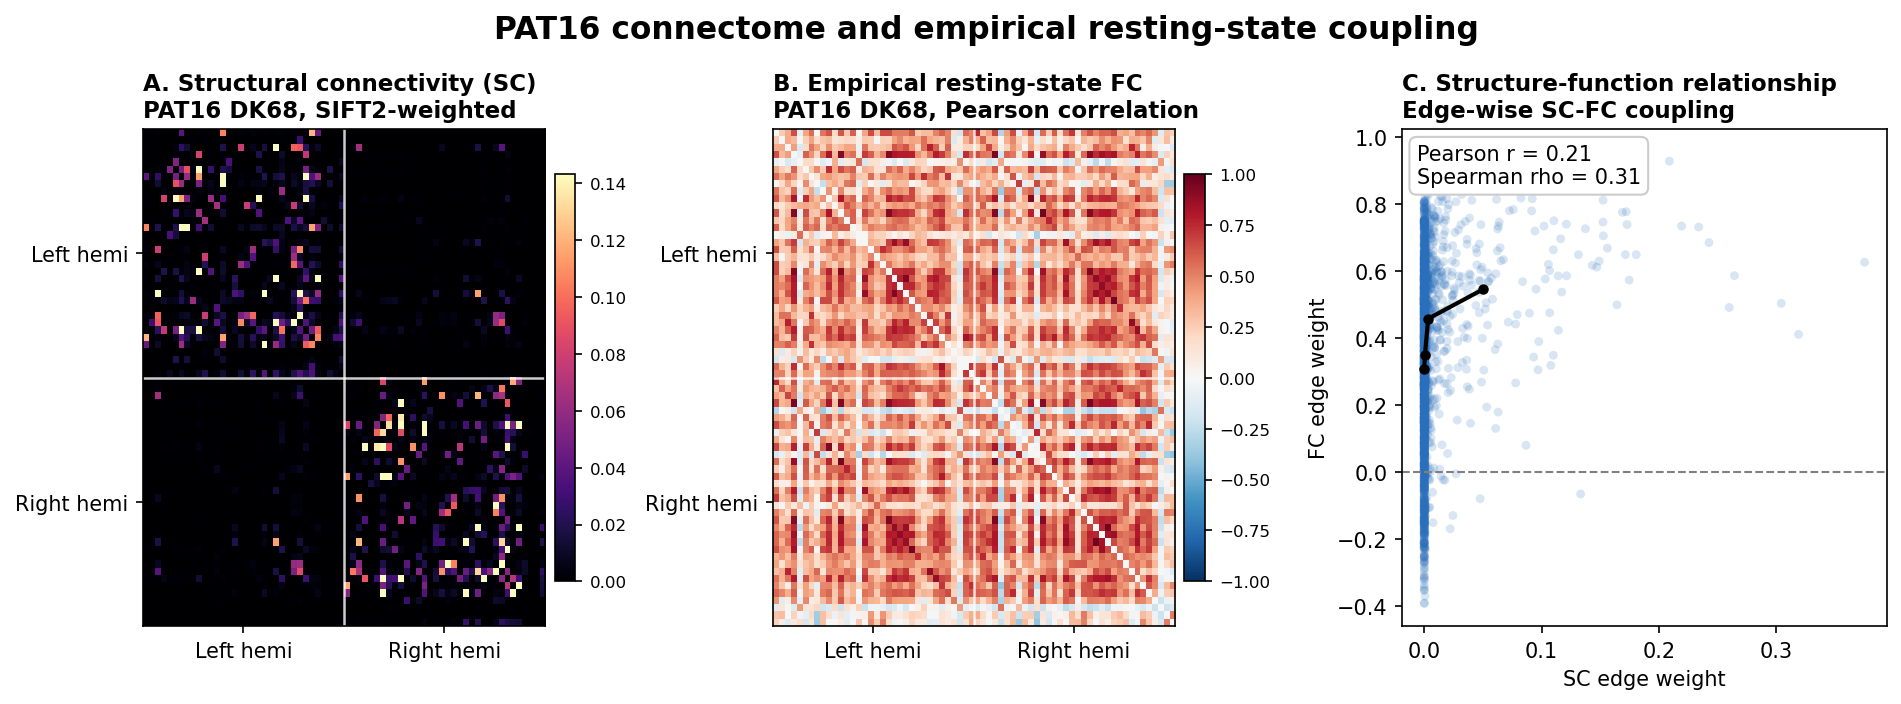

Saved figure: figures/capstone/pat16_intro_connectome_fc_summary.png


In [2]:
# Slide-ready Figure 1: structure, function, and their edge-wise relationship.

plt.rcParams.update({
    'figure.dpi': 150,
    'savefig.dpi': 300,
    'font.size': 10,
    'axes.titlesize': 12,
    'figure.facecolor': 'white',
})


def draw_matrix_panel(fig, ax, matrix, title, cmap, vmin, vmax):
    im = ax.imshow(matrix, cmap=cmap, vmin=vmin, vmax=vmax, aspect='auto')
    ax.axhline(33.5, color='white', lw=1.2, alpha=0.8)
    ax.axvline(33.5, color='white', lw=1.2, alpha=0.8)
    ax.set_xticks([16.5, 50.5])
    ax.set_xticklabels(['Left hemi', 'Right hemi'])
    ax.set_yticks([16.5, 50.5])
    ax.set_yticklabels(['Left hemi', 'Right hemi'])
    ax.set_title(title, loc='left', fontweight='bold', fontsize=11)
    cbar = fig.colorbar(im, ax=ax, shrink=0.82, pad=0.02)
    cbar.ax.tick_params(labelsize=8)
    return im


fig1, axes = plt.subplots(1, 3, figsize=(15.0, 4.8), constrained_layout=False)
fig1.subplots_adjust(top=0.80, wspace=0.30)

draw_matrix_panel(
    fig1,
    axes[0],
    SC_pre,
    'A. Structural connectivity (SC)\nPAT16 DK68, SIFT2-weighted',
    'magma',
    0,
    np.nanpercentile(SC_pre, 99),
)

draw_matrix_panel(
    fig1,
    axes[1],
    FC_empirical,
    'B. Empirical resting-state FC\nPAT16 DK68, Pearson correlation',
    'RdBu_r',
    -1,
    1,
)

ax = axes[2]
ax.scatter(sc_u[edge_mask], fc_u[edge_mask], s=18, alpha=0.18, color='#2a6fbb', edgecolor='none')
ax.axhline(0, color='0.5', lw=1, ls='--')

bins = np.quantile(sc_u[edge_mask], np.linspace(0, 1, 9))
bins[0] -= 1e-9
bins[-1] += 1e-9
xmid, ymean = [], []
for lo, hi in zip(bins[:-1], bins[1:]):
    m = (sc_u[edge_mask] >= lo) & (sc_u[edge_mask] < hi)
    if m.sum() >= 5:
        xmid.append(sc_u[edge_mask][m].mean())
        ymean.append(fc_u[edge_mask][m].mean())
ax.plot(xmid, ymean, '-o', color='black', lw=2, ms=4)
ax.set_xlabel('SC edge weight')
ax.set_ylabel('FC edge weight')
ax.set_title('C. Structure-function relationship\nEdge-wise SC-FC coupling', loc='left', fontweight='bold', fontsize=11)
ax.text(
    0.03,
    0.97,
    f'Pearson r = {sc_fc_r:.2f}\nSpearman rho = {sc_fc_rho:.2f}',
    transform=ax.transAxes,
    va='top',
    ha='left',
    bbox=dict(boxstyle='round,pad=0.35', fc='white', ec='0.8'),
)

fig1.suptitle('PAT16 connectome and empirical resting-state coupling', fontsize=15, fontweight='bold', y=0.96)
out_path1 = FIG_DIR / 'pat16_intro_connectome_fc_summary.png'
fig1.savefig(out_path1, bbox_inches='tight')
plt.show()
print(f'Saved figure: {out_path1}')

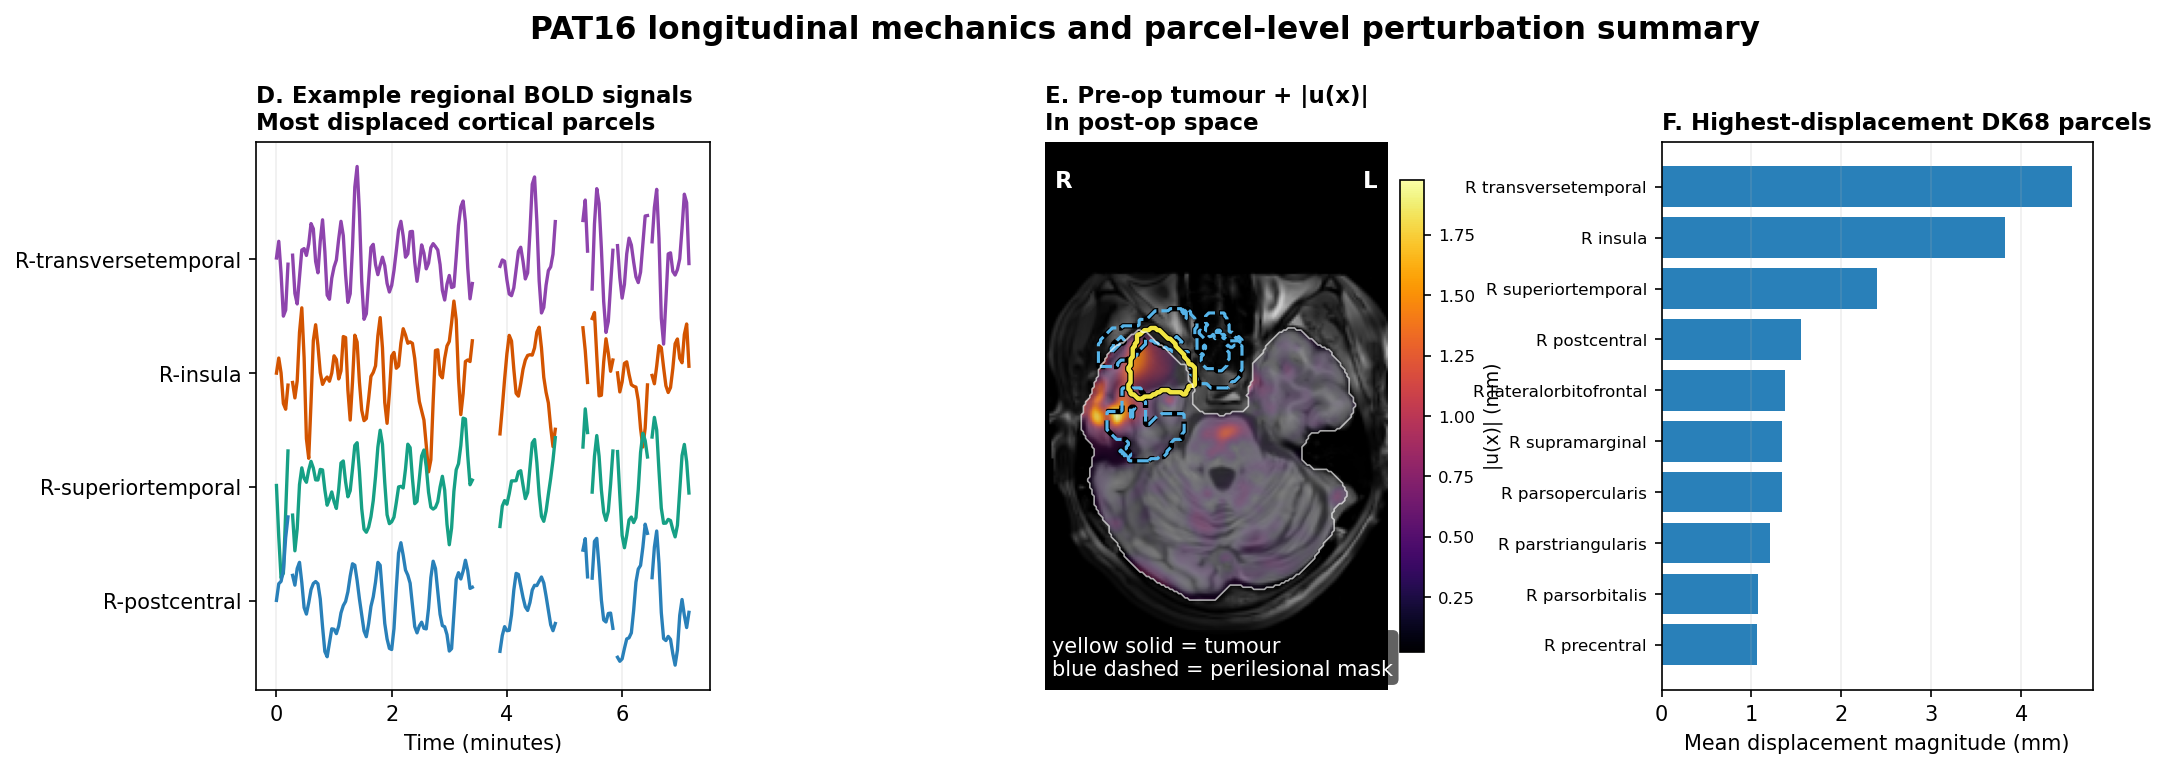

Saved figure: figures/capstone/pat16_intro_mechanics_summary.png


In [3]:
# Slide-ready Figure 2: regional signals, longitudinal mechanics, and parcel-level perturbation summary.

fig2, axes = plt.subplots(
    1,
    3,
    figsize=(15.8, 5.3),
    constrained_layout=False,
    gridspec_kw={'width_ratios': [1.00, 1.35, 0.95]},
)
fig2.subplots_adjust(top=0.80, wspace=0.34)

ax = axes[0]
offsets = 3.5 * np.arange(selected_ts.shape[1])[::-1]
colors = ['#8e44ad', '#d35400', '#16a085', '#2980b9']
for k in range(selected_ts.shape[1]):
    ax.plot(time_min, selected_ts[:, k] + offsets[k], lw=1.6, color=colors[k])
ax.set_xlabel('Time (minutes)')
ax.set_yticks(offsets)
ax.set_yticklabels(selected_names)
ax.set_title('D. Example regional BOLD signals\nMost displaced cortical parcels', loc='left', fontweight='bold', fontsize=11)
ax.grid(alpha=0.2, axis='x')

ax = axes[1]
# Show the axial slice in a conventional radiological layout:
# the left side of the image corresponds to the patient's right side.
base = t1_long[:, :, z_idx].T
over = disp_mag[:, :, z_idx].T
tum = tumor_mask[:, :, z_idx].T
peri = perilesional_mask[:, :, z_idx].T
brain = postop_brain_mask[:, :, z_idx].T > 0

over_masked = np.ma.masked_where(~brain, over)
scale_ref = np.nanpercentile(over[brain], 99) if np.any(brain) else np.nanpercentile(disp_mag[disp_mag > 0], 99)
alpha_map = np.ma.masked_where(~brain, np.clip(over / scale_ref, 0, 1) * 0.82)

ax.imshow(base, cmap='gray', origin='lower')
im = ax.imshow(over_masked, cmap='inferno', origin='lower', alpha=alpha_map)
ax.contour(peri.astype(float), levels=[0.5], colors=['black'], linewidths=2.6, linestyles='--')
ax.contour(peri.astype(float), levels=[0.5], colors=['#56B4E9'], linewidths=1.5, linestyles='--')
ax.contour(tum.astype(float), levels=[0.5], colors=['black'], linewidths=3.2)
ax.contour(tum.astype(float), levels=[0.5], colors=['#F0E442'], linewidths=2.1)
ax.contour(brain.astype(float), levels=[0.5], colors=['white'], linewidths=0.8, alpha=0.65)
ax.invert_xaxis()
ax.text(0.03, 0.95, 'R', transform=ax.transAxes, color='white', fontsize=11, fontweight='bold', va='top')
ax.text(0.97, 0.95, 'L', transform=ax.transAxes, color='white', fontsize=11, fontweight='bold', va='top', ha='right')
ax.set_title('E. Pre-op tumour + |u(x)|\nIn post-op space', loc='left', fontweight='bold', fontsize=11)
ax.text(
    0.02,
    0.02,
    'yellow solid = tumour\nblue dashed = perilesional mask',
    transform=ax.transAxes,
    ha='left',
    va='bottom',
    color='white',
    bbox=dict(boxstyle='round,pad=0.28', fc=(0, 0, 0, 0.62), ec='none'),
)
ax.set_axis_off()
cbar = fig2.colorbar(im, ax=ax, shrink=0.86, pad=0.02)
cbar.set_label('|u(x)| (mm)', fontsize=9)
cbar.ax.tick_params(labelsize=8)

ax = axes[2]
top10_idx = np.argsort(parcel_disp_mean)[-10:][::-1]
bar_colors = ['#c0392b' if name.startswith('L-') else '#2980b9' for name in np.array(roi_names_dk68)[top10_idx]]
short_roi_labels = [name.replace('L-', 'L ').replace('R-', 'R ') for name in np.array(roi_names_dk68)[top10_idx]]
ax.barh(np.arange(len(top10_idx)), parcel_disp_mean[top10_idx], color=bar_colors)
ax.set_yticks(np.arange(len(top10_idx)))
ax.set_yticklabels(short_roi_labels)
ax.invert_yaxis()
ax.set_xlabel('Mean displacement magnitude (mm)')
ax.set_title('F. Highest-displacement DK68 parcels', loc='left', fontweight='bold', fontsize=11)
ax.tick_params(axis='y', labelsize=8)
ax.grid(alpha=0.2, axis='x')

fig2.suptitle('PAT16 longitudinal mechanics and parcel-level perturbation summary', fontsize=15, fontweight='bold', y=0.96)
out_path2 = FIG_DIR / 'pat16_intro_mechanics_summary.png'
fig2.savefig(out_path2, bbox_inches='tight')
plt.show()
print(f'Saved figure: {out_path2}')

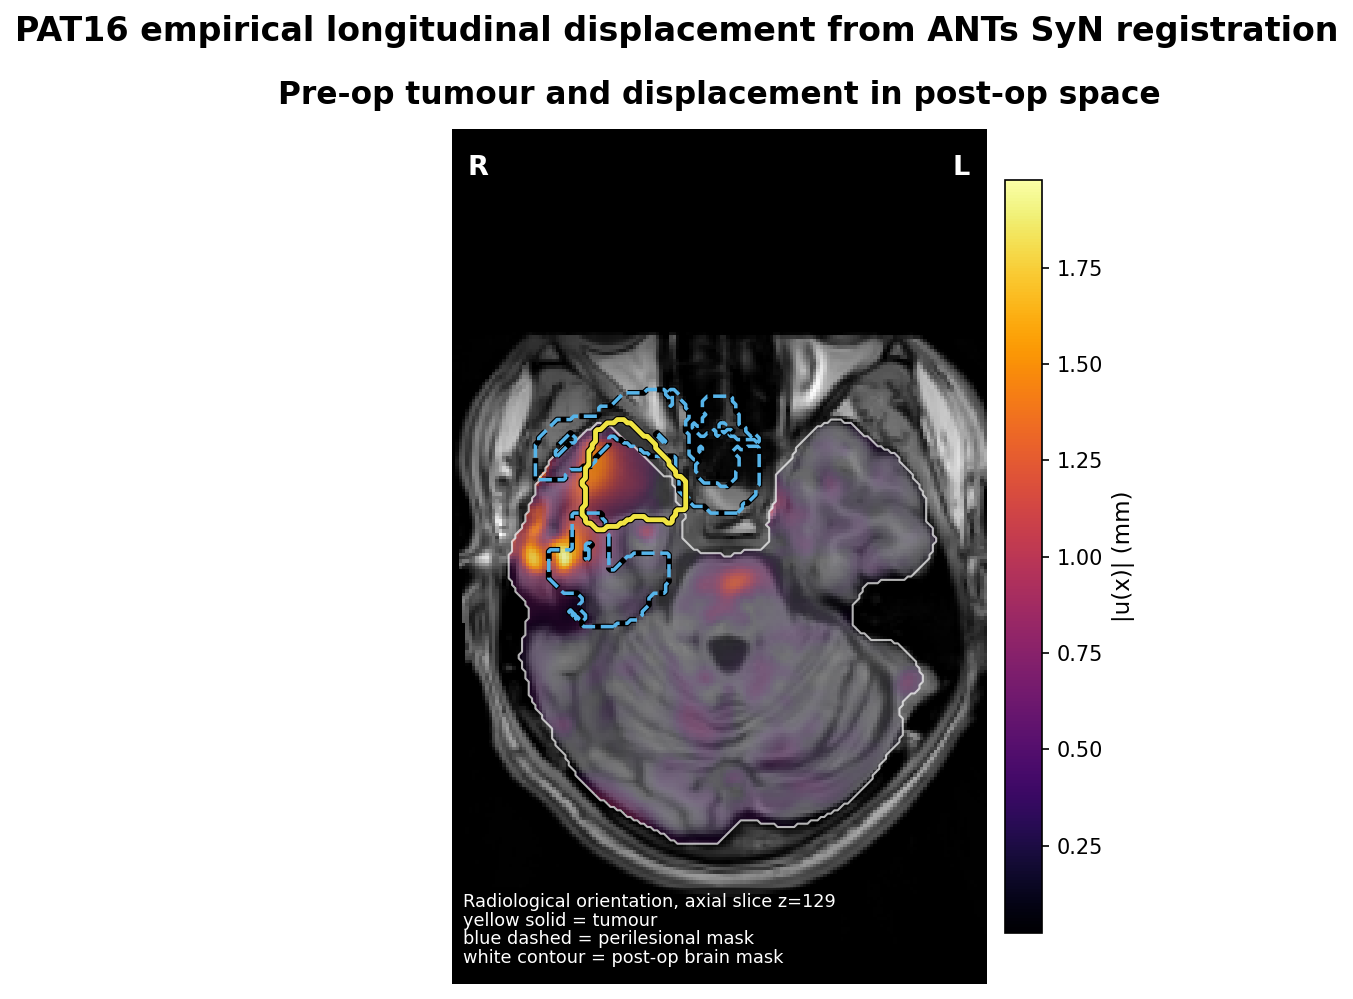

Saved figure: figures/capstone/pat16_panelE_displacement_detail.png
Saved figure: figures/capstone/pat16_panelE_displacement_detail.pdf


In [4]:
# Enlarged Panel E for slides: pre-op tumour and displacement in post-op space.

figE, ax = plt.subplots(1, 1, figsize=(8.2, 7.6), constrained_layout=False)
figE.subplots_adjust(top=0.86, right=0.88)

base = t1_long[:, :, z_idx].T
over = disp_mag[:, :, z_idx].T
tum = tumor_mask[:, :, z_idx].T
peri = perilesional_mask[:, :, z_idx].T
brain = postop_brain_mask[:, :, z_idx].T > 0

over_masked = np.ma.masked_where(~brain, over)
scale_ref = np.nanpercentile(over[brain], 99) if np.any(brain) else np.nanpercentile(disp_mag[disp_mag > 0], 99)
alpha_map = np.ma.masked_where(~brain, np.clip(over / scale_ref, 0, 1) * 0.84)

ax.imshow(base, cmap='gray', origin='lower')
im = ax.imshow(over_masked, cmap='inferno', origin='lower', alpha=alpha_map)
ax.contour(brain.astype(float), levels=[0.5], colors=['white'], linewidths=1.0, alpha=0.7)
ax.contour(peri.astype(float), levels=[0.5], colors=['black'], linewidths=2.8, linestyles='--')
ax.contour(peri.astype(float), levels=[0.5], colors=['#56B4E9'], linewidths=1.7, linestyles='--')
ax.contour(tum.astype(float), levels=[0.5], colors=['black'], linewidths=3.4)
ax.contour(tum.astype(float), levels=[0.5], colors=['#F0E442'], linewidths=2.3)
ax.invert_xaxis()
ax.text(0.03, 0.97, 'R', transform=ax.transAxes, color='white', fontsize=13, fontweight='bold', va='top')
ax.text(0.97, 0.97, 'L', transform=ax.transAxes, color='white', fontsize=13, fontweight='bold', va='top', ha='right')
ax.set_title('Pre-op tumour and displacement in post-op space', loc='center', fontweight='bold', fontsize=15, pad=12)
ax.text(
    0.02,
    0.02,
    f'Radiological orientation, axial slice z={z_idx}\nyellow solid = tumour\nblue dashed = perilesional mask\nwhite contour = post-op brain mask',
    transform=ax.transAxes,
    ha='left',
    va='bottom',
    color='white',
    fontsize=8.5,
    linespacing=1.05,
    bbox=dict(boxstyle='round,pad=0.28', fc=(0, 0, 0, 0.64), ec='none'),
)
ax.set_axis_off()

cbar = figE.colorbar(im, ax=ax, shrink=0.88, pad=0.02)
cbar.set_label('|u(x)| (mm)', fontsize=11)
cbar.ax.tick_params(labelsize=10)

figE.suptitle('PAT16 empirical longitudinal displacement from ANTs SyN registration', fontsize=16, fontweight='bold', y=0.96)
out_pathE_png = FIG_DIR / 'pat16_panelE_displacement_detail.png'
out_pathE_pdf = FIG_DIR / 'pat16_panelE_displacement_detail.pdf'
figE.savefig(out_pathE_png, bbox_inches='tight')
figE.savefig(out_pathE_pdf, bbox_inches='tight')
plt.show()
print(f'Saved figure: {out_pathE_png}')
print(f'Saved figure: {out_pathE_pdf}')

## Notes for panels A-F

The slide figures make the PAT16 modeling logic visible in a cleaner way: **SC** provides the anatomical scaffold, **rsFC** provides the empirical target, and **longitudinal mechanics** identifies where the glioma most plausibly perturbs the network substrate.

### Panel A. Structural connectivity

A **68 x 68 DK68 structural connectome** derived from diffusion MRI tractography with **ACT + SIFT2** weighting. Bright entries mark stronger streamline-supported coupling. The block structure shows that the connectome is modular rather than uniform, with prominent within-hemisphere organization and a smaller set of inter-hemispheric links. This is the network scaffold on which the Hopf dynamics evolve.

### Panel B. Empirical resting-state FC

A **68 x 68 Pearson-correlation matrix** computed from regional resting-state BOLD time series in the same DK68 parcels. Compared with SC, this matrix is denser and more spatially diffuse, which is expected: FC reflects distributed co-fluctuation, not just direct white-matter wiring. It is the empirical large-scale pattern the model aims to reproduce.

### Panel C. Structure-function coupling

Each dot compares one structural edge with the matching empirical functional edge. The positive but modest trend is scientifically useful: anatomy clearly constrains function, but does not determine it exactly. That is the regime where a whole-brain dynamical model is needed, because regional operating points, noise, and network interactions matter in addition to wiring.

### Panel D. Example regional BOLD signals

These are standardized resting-state BOLD traces from a few of the most mechanically displaced cortical parcels. The panel is a reminder that FC is not measured directly; it is computed from pairwise relationships between time courses like these. For slide purposes, this panel links the abstract FC matrix back to the underlying regional signals.

### Panel E. Pre-op tumour + displacement in post-op space

This axial slice is shown in **radiological orientation**. The grayscale background is the **pre-op T1 warped into post-op longitudinal space**. The **yellow solid contour** marks the pre-op tumour, the **blue dashed contour** marks the perilesional mask, and the hot colormap shows empirical displacement magnitude.

In this project, the displacement field comes from **ANTs SyN diffeomorphic longitudinal registration** of **pre-op -> post-op** T1w MRI. The script runs `antsRegistrationSyN.sh` with the post-op scan as fixed image and the pre-op scan as moving image, producing:

- a forward nonlinear warp `preop_to_postop_1Warp.nii.gz`,
- an inverse warp `preop_to_postop_1InverseWarp.nii.gz`,
- and a separate affine transform `preop_to_postop_0GenericAffine.mat`.

The voxelwise vector field stored in the forward warp provides the three components

$$
\mathbf{u}(\mathbf{x}) = \big(u_x(\mathbf{x}), u_y(\mathbf{x}), u_z(\mathbf{x})\big),
$$

and the displayed scalar map is its Euclidean norm

$$
|\mathbf{u}(\mathbf{x})| = \sqrt{u_x(\mathbf{x})^2 + u_y(\mathbf{x})^2 + u_z(\mathbf{x})^2}.
$$

So `u_x`, `u_y`, and `u_z` are not hand-estimated components; they are the Cartesian components of the dense **nonlinear SyN warp field** output by ANTs. In the repository, `displacement_magnitude.nii.gz` is computed directly from that warp image. For display, the overlay is clipped with the explicit **post-op fMRIPrep brain mask**, so deformation outside the brain is suppressed. This panel is the key mechanics-to-dynamics bridge: it shows where tissue has moved and therefore where regional coupling or excitability may need to be perturbed.

### Panel F. Most perturbed DK68 parcels

A ranking of cortical DK68 parcels by **mean displacement magnitude**. This is the parcel-level summary of Panel E. The important interpretation is that mechanical perturbation is spatially heterogeneous, not global, so the neural model should not treat all regions as equally affected by the lesion.

### Slide takeaway

Together, Panels A-F tell a compact patient-specific story: the PAT16 connectome defines the allowable routes for interaction, rsFC defines the observed large-scale functional organization, and the longitudinal displacement field identifies where glioma-related perturbation is strongest. The Hopf model is then used to test whether those ingredients can jointly explain the observed resting-state network pattern.

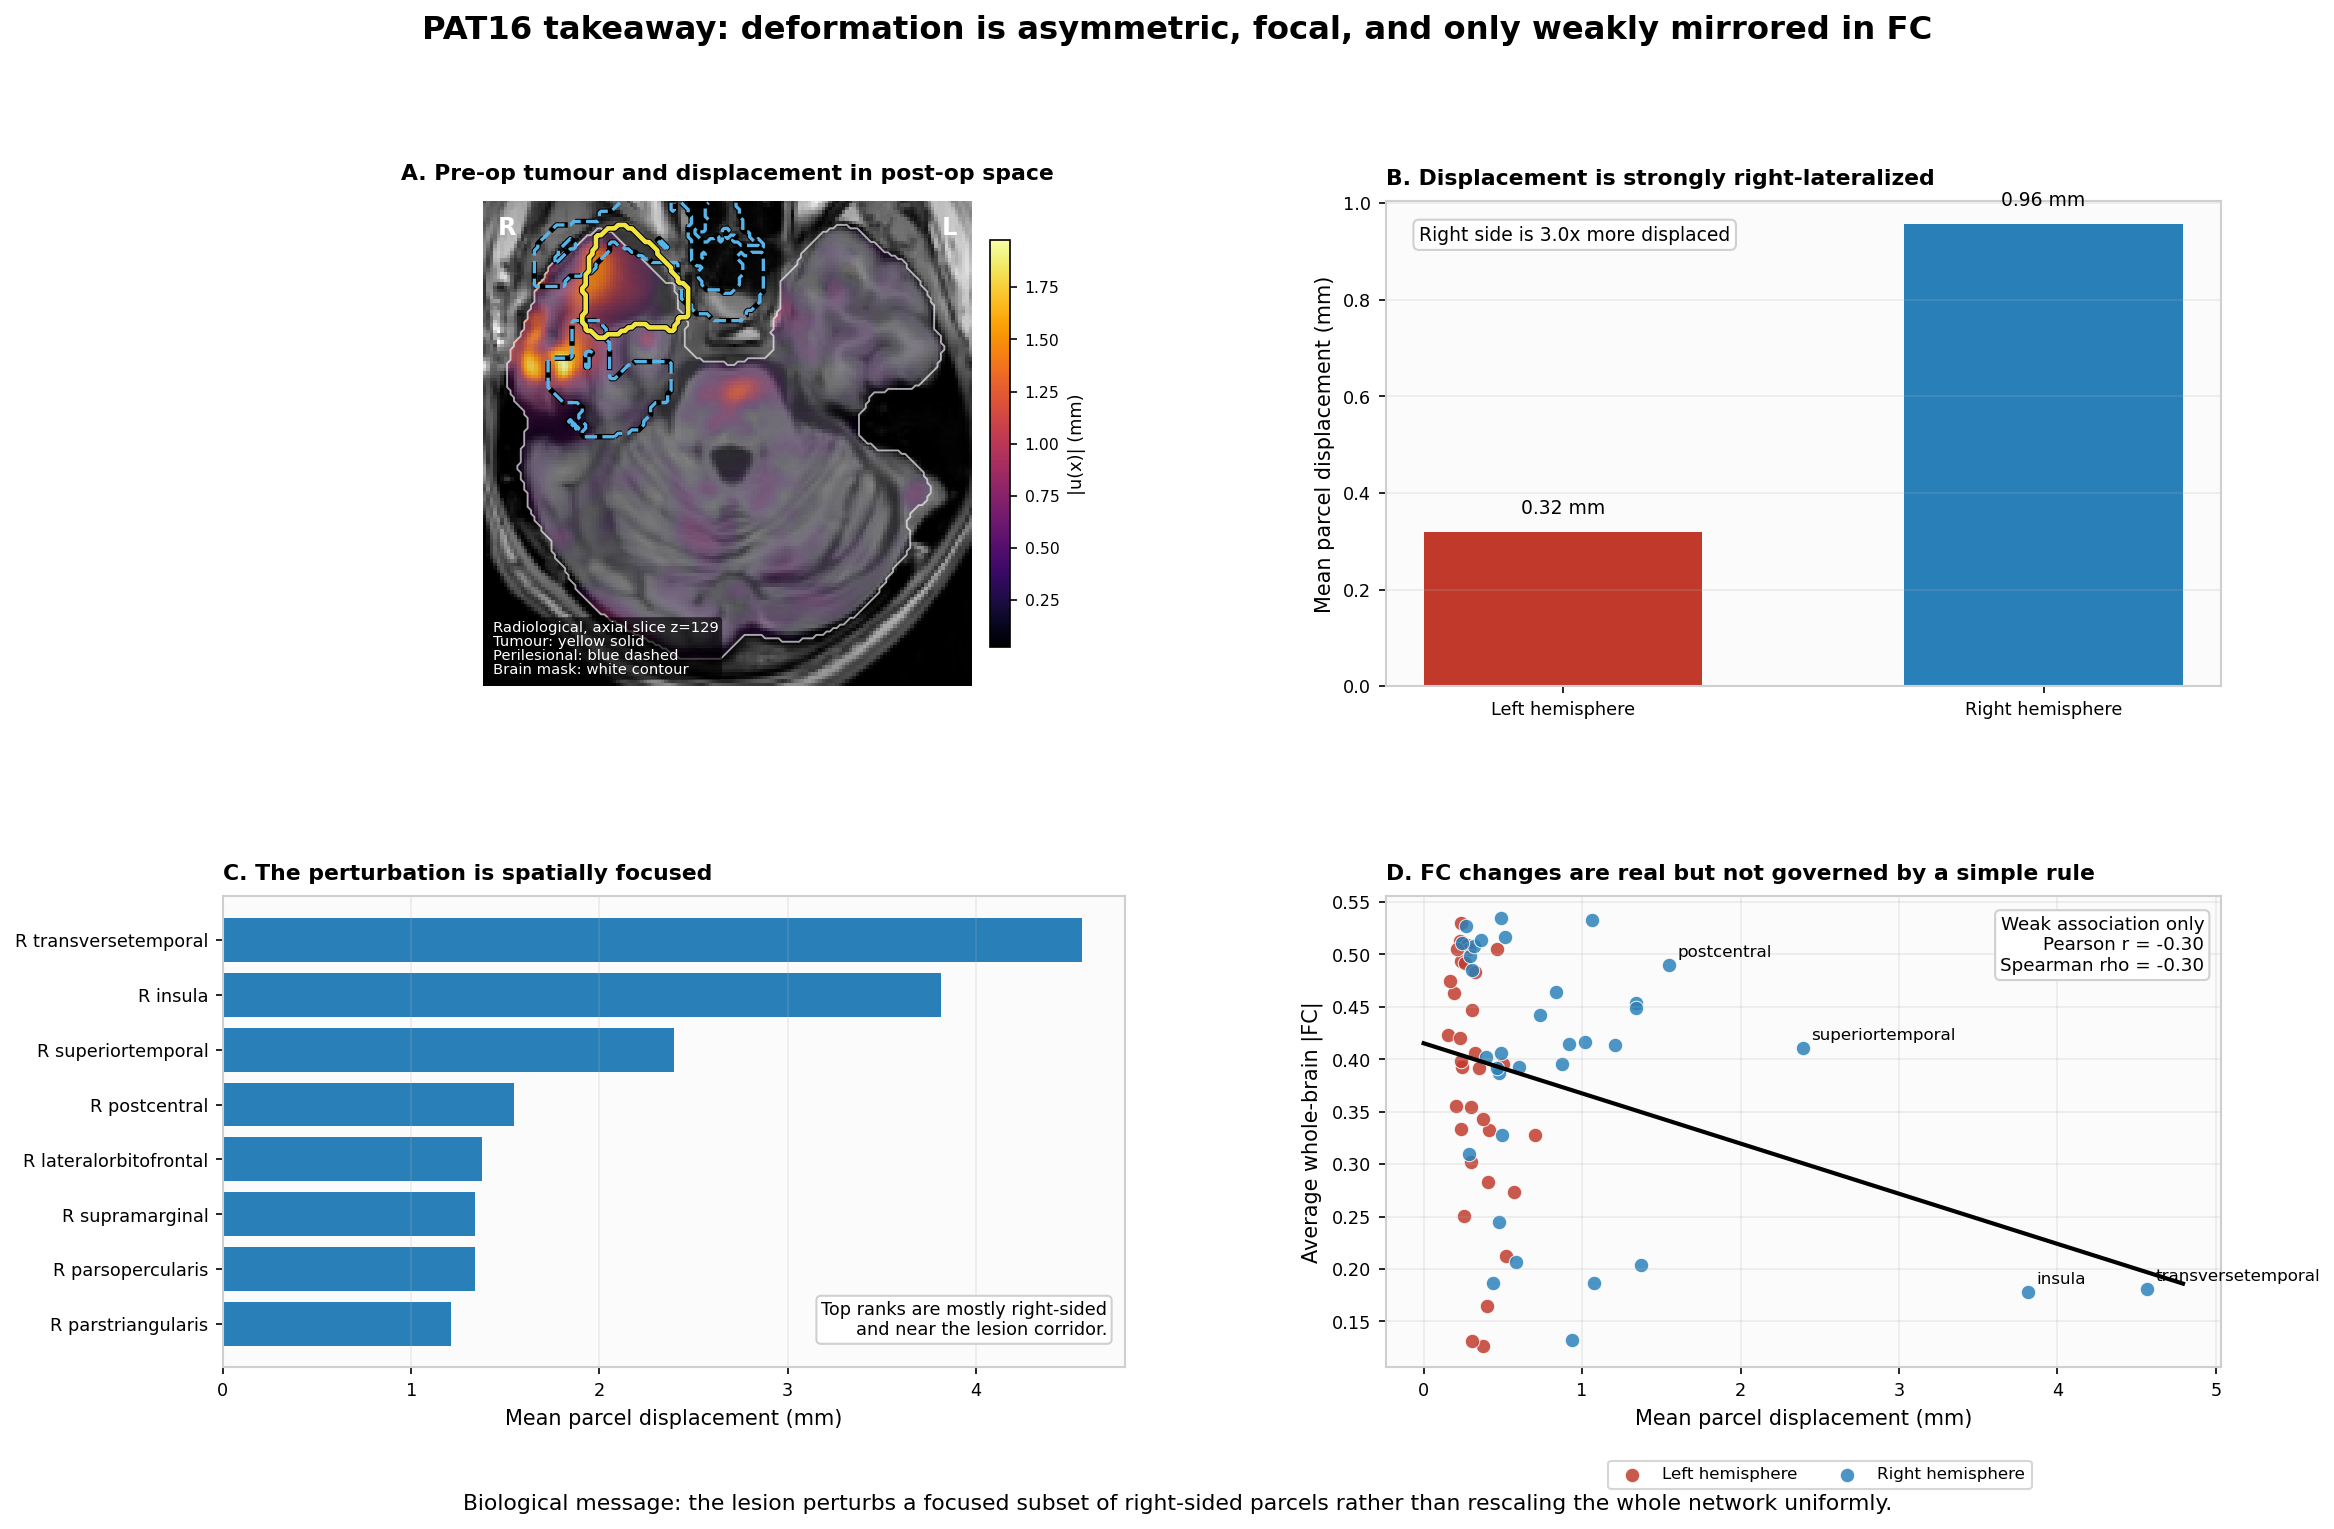

Saved figure: figures/capstone/pat16_mechanics_biological_takeaway.png
Saved figure: figures/capstone/pat16_mechanics_biological_takeaway.pdf
Left vs right mean displacement: 0.318 mm vs 0.956 mm
Displacement vs mean |FC|: Pearson r = -0.300, Spearman rho = -0.304


In [5]:
# Didactic slide figure: biological takeaway from mechanics in PAT16.

left_disp_mean = np.nanmean(parcel_disp_mean[:34])
right_disp_mean = np.nanmean(parcel_disp_mean[34:])
disp_ratio = right_disp_mean / left_disp_mean if left_disp_mean > 0 else np.nan

fc_disp_r = pearsonr(parcel_disp_mean, fc_strength).statistic
fc_disp_rho = spearmanr(parcel_disp_mean, fc_strength).statistic
trend_x = np.linspace(0, np.nanmax(parcel_disp_mean) * 1.05, 100)
trend_coef = np.polyfit(parcel_disp_mean, fc_strength, deg=1)
trend_y = np.polyval(trend_coef, trend_x)

top8_idx = np.argsort(parcel_disp_mean)[-8:][::-1]
short_top8 = [name.replace('L-', 'L ').replace('R-', 'R ') for name in np.array(roi_names_dk68)[top8_idx]]
annot_idx = np.argsort(parcel_disp_mean)[-4:]

fig, axes = plt.subplots(
    2,
    2,
    figsize=(14.8, 10.8),
    constrained_layout=False,
    gridspec_kw={'width_ratios': [1.08, 1.00], 'height_ratios': [1.03, 1.0]},
)
fig.subplots_adjust(top=0.86, bottom=0.14, left=0.07, right=0.97, wspace=0.30, hspace=0.44)

for ax in axes.ravel():
    ax.set_facecolor('#fbfbfb')
    for spine in ax.spines.values():
        spine.set_color('#cfcfcf')
        spine.set_linewidth(1.0)
    ax.tick_params(labelsize=8.5)

# Panel A: show where the perturbation sits anatomically.
ax = axes[0, 0]
base = t1_long[:, :, z_idx].T
over = disp_mag[:, :, z_idx].T
tum = tumor_mask[:, :, z_idx].T
peri = perilesional_mask[:, :, z_idx].T
brain = postop_brain_mask[:, :, z_idx].T > 0

# Crop to the brain-mask bounding box so the anatomy fills more of the panel.
brain_rows, brain_cols = np.where(brain)
row_min = max(int(brain_rows.min()) - 8, 0)
row_max = min(int(brain_rows.max()) + 8, brain.shape[0])
col_min = max(int(brain_cols.min()) - 8, 0)
col_max = min(int(brain_cols.max()) + 8, brain.shape[1])

base = base[row_min:row_max, col_min:col_max]
over = over[row_min:row_max, col_min:col_max]
tum = tum[row_min:row_max, col_min:col_max]
peri = peri[row_min:row_max, col_min:col_max]
brain = brain[row_min:row_max, col_min:col_max]

over_masked = np.ma.masked_where(~brain, over)
scale_ref = np.nanpercentile(over[brain], 99) if np.any(brain) else np.nanpercentile(disp_mag[disp_mag > 0], 99)
alpha_map = np.ma.masked_where(~brain, np.clip(over / scale_ref, 0, 1) * 0.84)
ax.imshow(base, cmap='gray', origin='lower')
im = ax.imshow(over_masked, cmap='inferno', origin='lower', alpha=alpha_map)
ax.contour(brain.astype(float), levels=[0.5], colors=['white'], linewidths=0.9, alpha=0.65)
ax.contour(peri.astype(float), levels=[0.5], colors=['black'], linewidths=2.6, linestyles='--')
ax.contour(peri.astype(float), levels=[0.5], colors=['#56B4E9'], linewidths=1.6, linestyles='--')
ax.contour(tum.astype(float), levels=[0.5], colors=['black'], linewidths=3.2)
ax.contour(tum.astype(float), levels=[0.5], colors=['#F0E442'], linewidths=2.2)
ax.invert_xaxis()
ax.text(0.03, 0.97, 'R', transform=ax.transAxes, color='white', fontsize=11.5, fontweight='bold', va='top')
ax.text(0.97, 0.97, 'L', transform=ax.transAxes, color='white', fontsize=11.5, fontweight='bold', va='top', ha='right')
ax.set_title('A. Pre-op tumour and displacement in post-op space', loc='center', fontweight='bold', fontsize=10.5, pad=10)
ax.text(
    0.02,
    0.02,
    f'Radiological, axial slice z={z_idx}\nTumour: yellow solid\nPerilesional: blue dashed\nBrain mask: white contour',
    transform=ax.transAxes,
    ha='left',
    va='bottom',
    color='white',
    fontsize=7.1,
    linespacing=1.0,
    bbox=dict(boxstyle='round,pad=0.22', fc=(0, 0, 0, 0.64), ec='none'),
)
ax.set_axis_off()
cbar = fig.colorbar(im, ax=ax, shrink=0.84, pad=0.02)
cbar.set_label('|u(x)| (mm)', fontsize=8.5)
cbar.ax.tick_params(labelsize=7.5)

# Panel B: hemisphere asymmetry is the clearest global summary.
ax = axes[0, 1]
hemi_vals = [left_disp_mean, right_disp_mean]
ax.bar(['Left hemisphere', 'Right hemisphere'], hemi_vals, color=['#c0392b', '#2980b9'], width=0.58)
ax.set_ylabel('Mean parcel displacement (mm)')
ax.set_title('B. Displacement is strongly right-lateralized', loc='left', fontweight='bold', fontsize=10.5, pad=8)
ax.grid(alpha=0.22, axis='y')
for i, val in enumerate(hemi_vals):
    ax.text(i, val + 0.03, f'{val:.2f} mm', ha='center', va='bottom', fontsize=9)
ax.text(
    0.04,
    0.95,
    f'Right side is {disp_ratio:.1f}x more displaced',
    transform=ax.transAxes,
    ha='left',
    va='top',
    fontsize=9,
    bbox=dict(boxstyle='round,pad=0.30', fc='white', ec='#d0d0d0'),
)

# Panel C: the perturbation is spatially selective, not uniform.
ax = axes[1, 0]
bar_colors = ['#c0392b' if label.startswith('L ') else '#2980b9' for label in short_top8]
ax.barh(np.arange(len(top8_idx)), parcel_disp_mean[top8_idx], color=bar_colors)
ax.set_yticks(np.arange(len(top8_idx)))
ax.set_yticklabels(short_top8)
ax.invert_yaxis()
ax.set_xlabel('Mean parcel displacement (mm)')
ax.set_title('C. The perturbation is spatially focused', loc='left', fontweight='bold', fontsize=10.5, pad=8)
ax.grid(alpha=0.22, axis='x')
ax.text(
    0.98,
    0.06,
    'Top ranks are mostly right-sided\nand near the lesion corridor.',
    transform=ax.transAxes,
    ha='right',
    va='bottom',
    fontsize=8.5,
    bbox=dict(boxstyle='round,pad=0.26', fc='white', ec='#d0d0d0'),
)

# Panel D: deformation does not map to FC strength by a simple global law.
ax = axes[1, 1]
for hemi, color, label in [('L-', '#c0392b', 'Left hemisphere'), ('R-', '#2980b9', 'Right hemisphere')]:
    mask = np.array([name.startswith(hemi) for name in roi_names_dk68])
    ax.scatter(
        parcel_disp_mean[mask],
        fc_strength[mask],
        s=48,
        alpha=0.84,
        color=color,
        edgecolor='white',
        linewidth=0.5,
        label=label,
    )
for i in annot_idx:
    ax.annotate(
        roi_names_dk68[i].replace('L-', '').replace('R-', ''),
        (parcel_disp_mean[i], fc_strength[i]),
        xytext=(4, 4),
        textcoords='offset points',
        fontsize=8,
    )
ax.plot(trend_x, trend_y, color='black', lw=2)
ax.set_xlabel('Mean parcel displacement (mm)')
ax.set_ylabel('Average whole-brain |FC|')
ax.set_title('D. FC changes are real but not governed by a simple rule', loc='left', fontweight='bold', fontsize=10.5, pad=8)
ax.grid(alpha=0.22)
ax.legend(frameon=True, fontsize=8, loc='upper center', bbox_to_anchor=(0.52, -0.18), ncol=2)
ax.text(
    0.98,
    0.96,
    f'Weak association only\nPearson r = {fc_disp_r:.2f}\nSpearman rho = {fc_disp_rho:.2f}',
    transform=ax.transAxes,
    ha='right',
    va='top',
    fontsize=8.8,
    bbox=dict(boxstyle='round,pad=0.28', fc='white', ec='#d0d0d0'),
)

fig.suptitle('PAT16 takeaway: deformation is asymmetric, focal, and only weakly mirrored in FC', fontsize=15.5, fontweight='bold', y=0.975)
fig.text(
    0.5,
    0.052,
    'Biological message: the lesion perturbs a focused subset of right-sided parcels rather than rescaling the whole network uniformly.',
    ha='center',
    fontsize=10.5,
)

out_path_png = FIG_DIR / 'pat16_mechanics_biological_takeaway.png'
out_path_pdf = FIG_DIR / 'pat16_mechanics_biological_takeaway.pdf'
fig.savefig(out_path_png, bbox_inches='tight')
fig.savefig(out_path_pdf, bbox_inches='tight')
plt.show()
print(f'Saved figure: {out_path_png}')
print(f'Saved figure: {out_path_pdf}')
print(f'Left vs right mean displacement: {left_disp_mean:.3f} mm vs {right_disp_mean:.3f} mm')
print(f'Displacement vs mean |FC|: Pearson r = {fc_disp_r:.3f}, Spearman rho = {fc_disp_rho:.3f}')

## Notes for the biological takeaway figure

This figure is designed to answer one teaching question directly: **how does lesion-related mechanics appear to organize the large-scale perturbation pattern in PAT16?**

### Panel A. The mechanical perturbation is anatomically focal

**What is shown:** an axial mechanics view in post-op space, with tumour outline, perilesional mask, and empirical displacement magnitude.

**Why it matters:** this panel anchors the takeaway in anatomy before moving to summary statistics. It shows that the perturbation is not abstract; it is spatially localized around the lesion corridor.

**Interpretation:** the displacement field is strongest in a focal anatomical neighborhood rather than being spread uniformly across the brain. That is the spatial starting point for any mechanics-informed perturbation model.

### Panel B. Displacement is strongly right-lateralized

**What is shown:** the mean DK68 parcel displacement, averaged separately over the left and right hemispheres.

**Why it matters:** this is the clearest global summary of the mechanics data. It shows that displacement is not balanced across the brain; in PAT16 it is clearly stronger in the **right hemisphere**.

**Interpretation:** the tumour-related mechanical effect is laterally asymmetric. That makes a uniform whole-brain perturbation biologically implausible. A patient-specific model should therefore allow stronger perturbation on the more displaced side.

### Panel C. The perturbation is spatially focused

**What is shown:** the cortical DK68 parcels with the largest mean displacement values.

**Why it matters:** this panel converts the deformation field into anatomically named candidate regions for perturbation in the neural model.

**Interpretation:** the effect is spatially selective, not diffuse. The most displaced parcels are predominantly **right-sided** and cluster near the lesion corridor. This supports a modeling strategy in which only a subset of parcels receives strong mechanics-informed changes in coupling or bifurcation parameters.

### Panel D. FC changes are real but not governed by a simple rule

**What is shown:** parcel displacement versus each parcel's average whole-brain functional coupling strength, with left and right hemispheres separated by color and a fitted trend line for visual guidance.

**Why it matters:** this tests a simple hypothesis: if mechanics alone dominated the functional effect, then more displaced parcels should show a strong monotonic change in FC strength.

**Interpretation:** the relationship is only **weak to modest**. That is biologically important. It suggests that displacement helps localize vulnerable regions, but does not by itself determine functional organization through a simple global rule. Neural dynamics, network context, and possibly neurovascular effects still matter.

### Overall slide takeaway

The biological message is that PAT16 does not show a uniform mechanics-to-function scaling law. Instead, the longitudinal displacement field identifies a **focal, right-lateralized perturbation pattern**, while the functional consequences remain **distributed and region-dependent**. That is exactly the setting where a whole-brain dynamical model is useful: it can propagate a localized mechanics-informed perturbation through the connectome and test whether the resulting network effects resemble the observed rsFC.

## Key messages

- **This notebook works at the macroscale:** each DK68 cortical parcel is modeled as one dynamical node in a patient-specific whole-brain network.
- **PAT16-specific structure matters:** diffusion MRI tractography provides the anatomical coupling scaffold that constrains how activity can spread across the brain.
- **PAT16-specific function matters:** resting-state fMRI provides empirical regional co-fluctuation patterns that the model aims to reproduce.
- **Glioma-related mechanics matters:** tumour-induced deformation and mass effect are used to perturb connectivity and/or local dynamical operating points.
- **The central hypothesis is integrative:** in PAT16, observed rsFC emerges from the interaction between anatomy, neural dynamics, and lesion-related mechanical perturbation.

---
## 1. From Single Neurons to Neural Mass Models

The brain contains ~86 billion neurons, each with thousands of synaptic
connections. Simulating individual neurons is computationally prohibitive
for a whole-brain model. Instead, **neural mass models** describe the
collective behaviour of neural populations using mean-field equations.

### Hierarchy of neural models

| Level | Scale | Model | State variable |
|-------|-------|-------|----------------|
| Microscale | Single neuron | Hodgkin-Huxley | Membrane potential $V_m$ |
| Mesoscale | Neural population (~10$^5$ neurons) | Wilson-Cowan, Jansen-Rit | Firing rate, PSP |
| Macroscale | Brain region (cortical parcel) | **Hopf normal form** | Complex amplitude $z$ |

### The Hopf Bifurcation Model

The **Hopf normal form** (Deco et al., 2017) captures the essential
dynamics of a cortical region near a supercritical Hopf bifurcation:

$$\frac{dz_i}{dt} = (\lambda_i + i\omega_i)\,z_i - z_i\,|z_i|^2 + J \sum_j \text{SC}(i,j)\,(z_j - z_i) + \eta_i(t)$$

where:
- $z_i \in \mathbb{C}$ is the complex-valued state of region $i$
- $\lambda_i$ is the **bifurcation parameter** (excitation-inhibition balance)
  - $\lambda_i < 0$: subcritical (noisy, no oscillation)
  - $\lambda_i > 0$: supercritical (sustained oscillation with amplitude $\sqrt{\lambda_i}$)
- $\omega_i$ is the natural frequency (~40 rad/s, corresponding to ~6 Hz)
- $J$ is the global coupling strength
- $\text{SC}(i,j)$ is the structural connectivity matrix
- $\eta_i(t)$ is complex Gaussian noise

### Why Hopf?

The Hopf model is appealing because:
1. **Single control parameter** ($\lambda$) determines the dynamical regime
2. **Biologically interpretable**: $\lambda$ reflects E/I balance
3. **Generates realistic FC**: the model predicts FC from SC
4. **Mechanically perturbable**: tissue compression can shift $\lambda$

In [6]:
import os
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from scipy.io import loadmat
import nibabel as nib
import sys
from pathlib import Path
import warnings
warnings.filterwarnings('ignore')

# ── Colab / local environment setup ─────────────────────────────────────────
if 'google.colab' in sys.modules:
    REPO_ROOT = Path('/content/glioma-brain-digital-twin')
    if not REPO_ROOT.exists():
        import subprocess
        _clone_result = subprocess.run(
            ['git', 'clone', '--depth', '1',
             'https://github.com/arvidl/glioma-brain-digital-twin-public.git',
             str(REPO_ROOT)],
            capture_output=True, text=True)
        if _clone_result.returncode != 0:
            raise RuntimeError(f'git clone failed: {_clone_result.stderr}')
    !pip install -q -r {REPO_ROOT}/environment/requirements-colab.txt
    if not (REPO_ROOT / 'data' / 'BIDS_preop_postop' / 'sub-PAT16').exists():
        !python {REPO_ROOT}/data/download_data.py --capstone
    os.chdir(REPO_ROOT)
else:
    _cwd = Path.cwd().resolve()
    REPO_ROOT = _cwd if (_cwd / 'pyproject.toml').exists() else _cwd.parent

sys.path.insert(0, str(REPO_ROOT))

BIDS_ROOT  = REPO_ROOT / 'data' / 'BIDS_preop_postop'
DERIV_PROJ = REPO_ROOT / 'derivatives'
REG_DIR    = DERIV_PROJ / 'registered_t1w' / 'sub-PAT16'
LONG_DIR   = REG_DIR / 'longitudinal'
CONN_DIR   = DERIV_PROJ / 'connectivity' / 'sub-PAT16'
TVB_DIR    = BIDS_ROOT / 'derivatives' / 'TVB' / 'sub-PAT16'
FIG_DIR    = Path('figures') / 'capstone'
FIG_DIR.mkdir(parents=True, exist_ok=True)

plt.rcParams.update({'figure.dpi': 150, 'savefig.dpi': 300,
                     'font.size': 10, 'axes.titlesize': 12,
                     'figure.facecolor': 'white'})

DK68_NAMES_LH = [
    'bankssts','caudalanteriorcingulate','caudalmiddlefrontal',
    'cuneus','entorhinal','fusiform','inferiorparietal',
    'inferiortemporal','isthmuscingulate','lateraloccipital',
    'lateralorbitofrontal','lingual','medialorbitofrontal',
    'middletemporal','parahippocampal','paracentral',
    'parsopercularis','parsorbitalis','parstriangularis',
    'pericalcarine','postcentral','posteriorcingulate',
    'precentral','precuneus','rostralanteriorcingulate',
    'rostralmiddlefrontal','superiorfrontal','superiorparietal',
    'superiortemporal','supramarginal','frontalpole',
    'temporalpole','transversetemporal','insula']
DK68_NAMES = [f'lh-{n}' for n in DK68_NAMES_LH] + \
             [f'rh-{n}' for n in DK68_NAMES_LH]
N_REGIONS = 68

LH_LABEL_IDS = [1001,1002,1003,1005,1006,1007,1008,1009,1010,1011,
                1012,1013,1014,1015,1016,1017,1018,1019,1020,1021,
                1022,1023,1024,1025,1026,1027,1028,1029,1030,1031,
                1032,1033,1034,1035]
RH_LABEL_IDS = [lid + 1000 for lid in LH_LABEL_IDS]
DK68_LABEL_IDS = LH_LABEL_IDS + RH_LABEL_IDS

In [7]:
# Load SC and FC from pipeline
sc_mat_path = TVB_DIR / 'ses-preop' / 'SCthrAn.mat'
if sc_mat_path.exists():
    sc_data = loadmat(str(sc_mat_path))
    for _k in ('SC_thr', 'SCthrAn', 'SC', 'weights'):
        if _k in sc_data:
            SC_pre = sc_data[_k].astype(float); break
    else:
        for _k, _v in sc_data.items():
            if isinstance(_v, np.ndarray) and _v.ndim == 2 and _v.shape[0] == _v.shape[1]:
                SC_pre = _v.astype(float); break
else:
    SC_pre = np.load(str(CONN_DIR / 'ses-preop' / 'sc_sift2.npy'))[:N_REGIONS, :N_REGIONS]

SC_pre_norm = SC_pre / SC_pre.max() if SC_pre.max() > 0 else SC_pre
N_REGIONS = SC_pre.shape[0]

fc_mat_path = TVB_DIR / 'ses-preop' / 'FC.mat'
if fc_mat_path.exists():
    fc_data = loadmat(str(fc_mat_path))
    for _k in ('FC', 'fc', 'R', 'corr'):
        if _k in fc_data:
            FC_empirical = fc_data[_k].astype(float); break
    else:
        for _k, _v in fc_data.items():
            if isinstance(_v, np.ndarray) and _v.ndim == 2 and _v.shape[0] == _v.shape[1]:
                FC_empirical = _v.astype(float); break
else:
    FC_empirical = np.load(str(CONN_DIR / 'ses-preop' / 'fc_pearson.npy'))[:N_REGIONS, :N_REGIONS]

# Load FEM displacement
fem_impr_vol = np.asarray(nib.load(str(LONG_DIR / 'fem_displacement_improved.nii.gz')).dataobj).astype(np.float32)

print(f'SC: {SC_pre.shape}, FC: {FC_empirical.shape}')
print(f'FEM displacement: {fem_impr_vol.shape}')

SC: (68, 68), FC: (68, 68)
FEM displacement: (171, 266, 266)


---
## 2. Baseline Hopf Simulation

We first run the Hopf model on the pre-operative SC matrix with uniform
parameters ($\lambda = 0.1$, $J = 0.05$) to produce a baseline
simulated FC.

In [8]:
def hopf_dynamics(z, SC, J=0.05, lambda_vals=None, omega=40.0, dt=1e-2):
    N = len(z)
    if lambda_vals is None:
        lambda_vals = np.full(N, 0.1)
    coupling = J * (SC @ z - SC.sum(axis=1) * z)
    noise = 0.01 * (np.random.randn(N) + 1j * np.random.randn(N))
    dzdt = (lambda_vals + 1j * omega) * z - z * np.abs(z)**2 + coupling + noise
    return z + dt * dzdt

np.random.seed(42)
z0 = 0.1 * (np.random.randn(N_REGIONS) + 1j * np.random.randn(N_REGIONS))
dt = 1e-3
T_sim = 2.0
N_steps = int(T_sim / dt)

# Baseline simulation
activity = np.zeros((N_REGIONS, N_steps))
z = z0.copy()
for step in range(N_steps):
    activity[:, step] = np.abs(z)
    z = hopf_dynamics(z, SC_pre_norm, J=0.05, dt=dt)

FC_simulated_pre = np.corrcoef(activity)
triu = np.triu_indices(N_REGIONS, 1)
r_sim_emp = np.corrcoef(FC_simulated_pre[triu], FC_empirical[triu])[0, 1]

print(f'Hopf simulation: {N_steps} steps, {T_sim:.1f}s')
print(f'Simulated-empirical FC correlation: r = {r_sim_emp:.3f}')

Hopf simulation: 2000 steps, 2.0s
Simulated-empirical FC correlation: r = 0.087


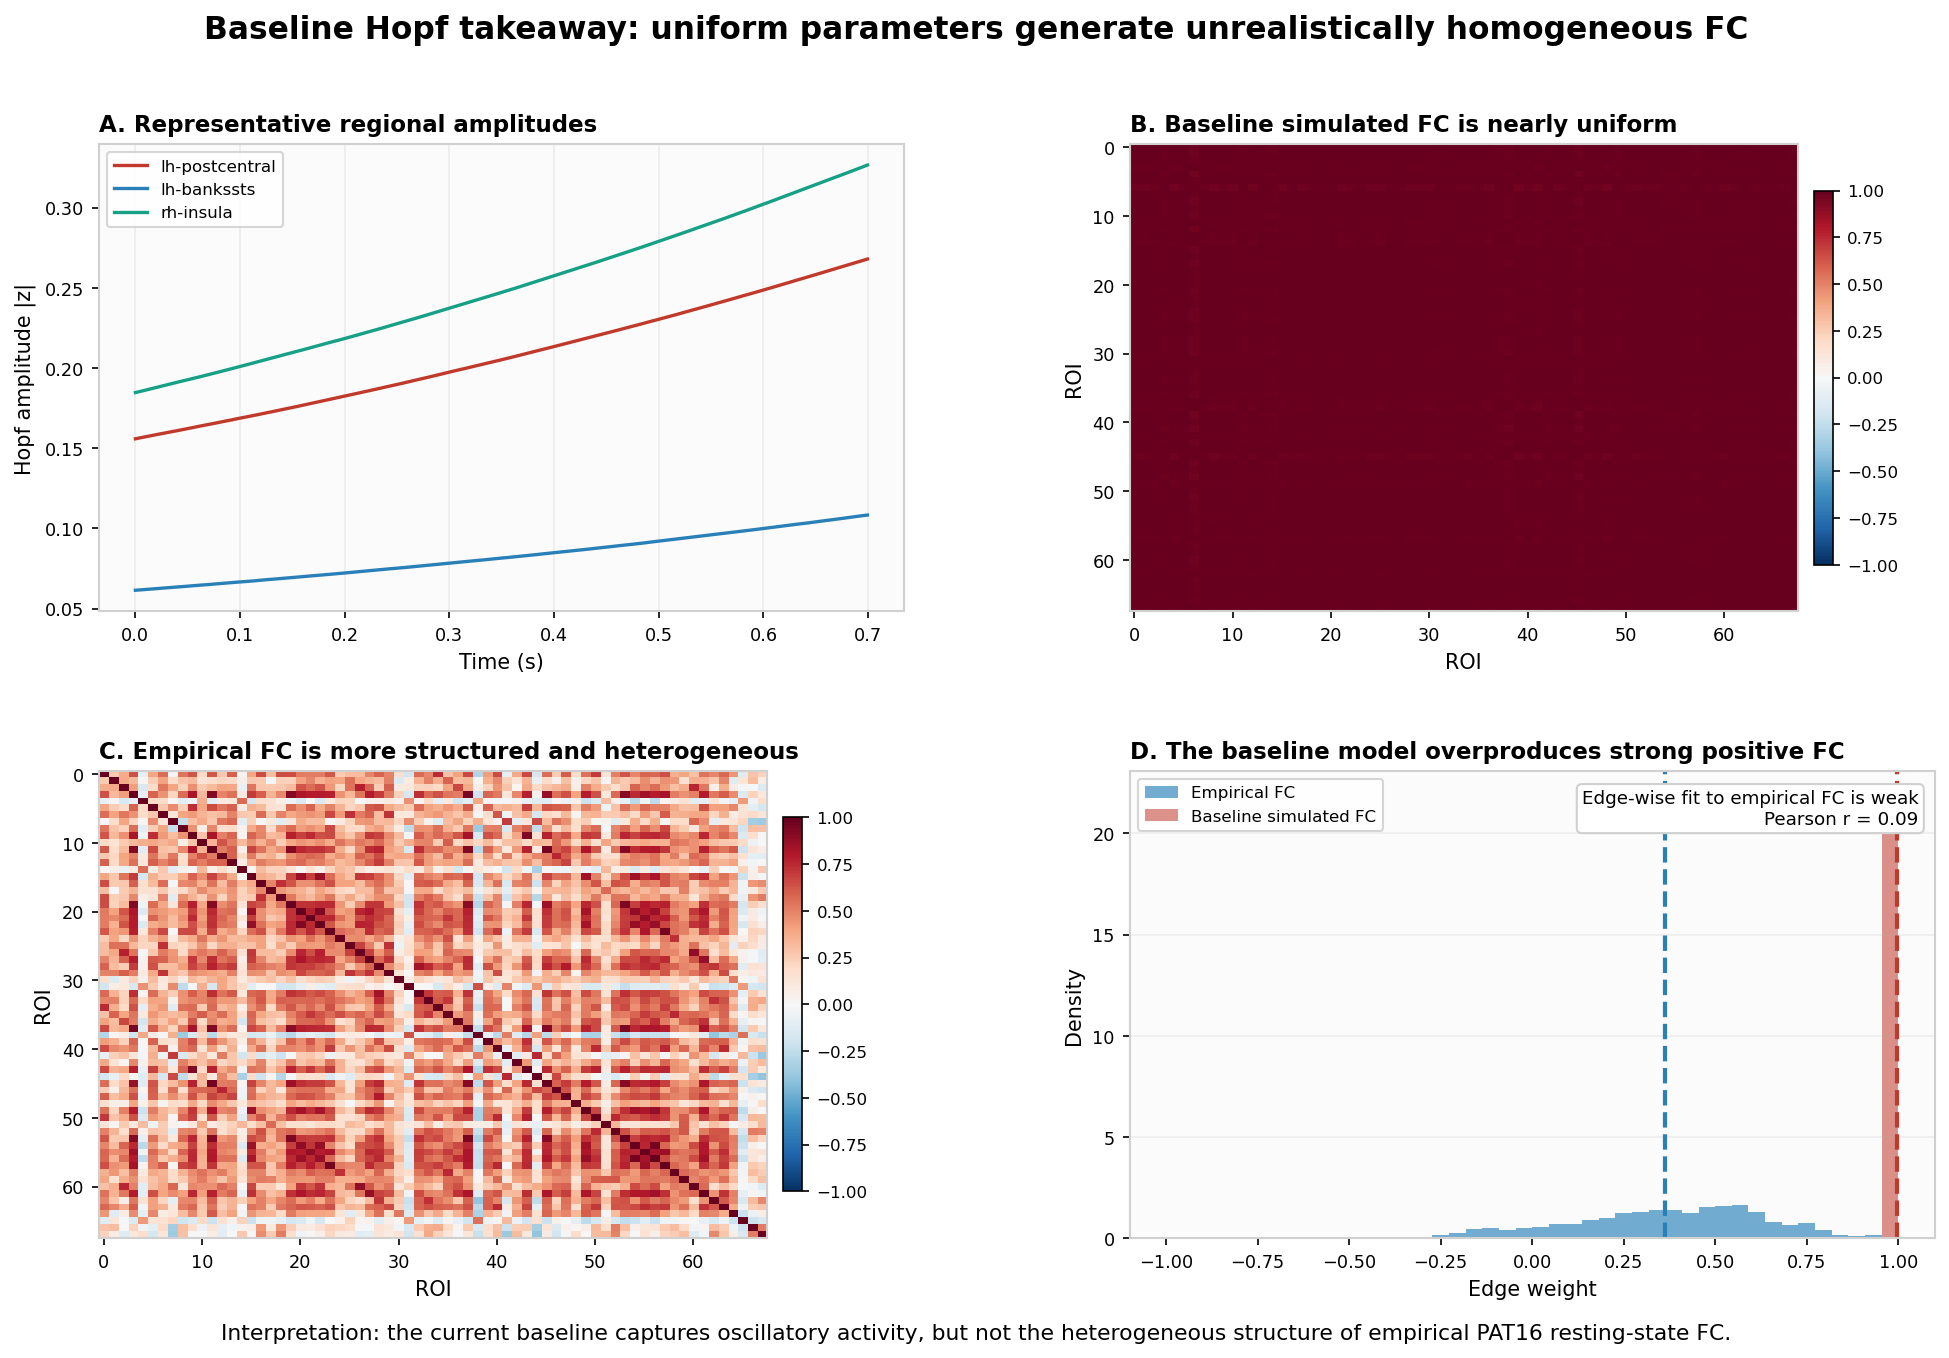

Saved figure: figures/capstone/figC07_01_hopf_baseline_takeaway.png
Saved figure: figures/capstone/figC07_01_hopf_baseline_takeaway.pdf


In [9]:
t_sim = np.linspace(0, T_sim, N_steps)

# Didactic baseline figure: show both the model output and why it currently fails.
def roi_index(name, fallback):
    return DK68_NAMES.index(name) if name in DK68_NAMES else fallback

roi_examples = [
    roi_index('lh-postcentral', 20),
    roi_index('lh-bankssts', 0),
    roi_index('rh-insula', N_REGIONS - 1),
]
roi_colors = ['#c0392b', '#2980b9', '#16a085']

fc_sim_edges = FC_simulated_pre[triu]
fc_emp_edges = FC_empirical[triu]

fig, axes = plt.subplots(2, 2, figsize=(13.6, 9.6), constrained_layout=False)
fig.subplots_adjust(top=0.88, bottom=0.12, left=0.07, right=0.97, wspace=0.28, hspace=0.34)

for ax in axes.ravel():
    ax.set_facecolor('#fbfbfb')
    for spine in ax.spines.values():
        spine.set_color('#d0d0d0')
        spine.set_linewidth(1.0)
    ax.tick_params(labelsize=8.5)

# Panel A: representative regional amplitudes.
ax = axes[0, 0]
for roi, color in zip(roi_examples, roi_colors):
    label = DK68_NAMES[roi] if roi < len(DK68_NAMES) else f'ROI {roi}'
    ax.plot(t_sim[:700], activity[roi, :700], lw=1.6, color=color, label=label)
ax.set_xlabel('Time (s)')
ax.set_ylabel('Hopf amplitude |z|')
ax.set_title('A. Representative regional amplitudes', loc='left', fontweight='bold', fontsize=11)
ax.legend(frameon=True, fontsize=8, loc='upper left')
ax.grid(alpha=0.20, axis='x')

# Panel B: simulated FC.
ax = axes[0, 1]
im = ax.imshow(FC_simulated_pre, cmap='RdBu_r', vmin=-1, vmax=1, aspect='auto')
ax.set_title('B. Baseline simulated FC is nearly uniform', loc='left', fontweight='bold', fontsize=11)
ax.set_xlabel('ROI')
ax.set_ylabel('ROI')
cbar = fig.colorbar(im, ax=ax, shrink=0.80, pad=0.02)
cbar.ax.tick_params(labelsize=8)

# Panel C: empirical FC for comparison.
ax = axes[1, 0]
im = ax.imshow(FC_empirical, cmap='RdBu_r', vmin=-1, vmax=1, aspect='auto')
ax.set_title('C. Empirical FC is more structured and heterogeneous', loc='left', fontweight='bold', fontsize=11)
ax.set_xlabel('ROI')
ax.set_ylabel('ROI')
cbar = fig.colorbar(im, ax=ax, shrink=0.80, pad=0.02)
cbar.ax.tick_params(labelsize=8)

# Panel D: edge-weight distributions explain the mismatch more clearly than a raw scatter.
ax = axes[1, 1]
bins = np.linspace(-1, 1, 45)
ax.hist(fc_emp_edges, bins=bins, density=True, alpha=0.65, color='#2980b9', label='Empirical FC')
ax.hist(fc_sim_edges, bins=bins, density=True, alpha=0.55, color='#c0392b', label='Baseline simulated FC')
ax.axvline(np.mean(fc_emp_edges), color='#2980b9', lw=2, ls='--')
ax.axvline(np.mean(fc_sim_edges), color='#c0392b', lw=2, ls='--')
ax.set_xlabel('Edge weight')
ax.set_ylabel('Density')
ax.set_title('D. The baseline model overproduces strong positive FC', loc='left', fontweight='bold', fontsize=11)
ax.legend(frameon=True, fontsize=8, loc='upper left')
ax.text(
    0.98,
    0.96,
    f'Edge-wise fit to empirical FC is weak\nPearson r = {r_sim_emp:.2f}',
    transform=ax.transAxes,
    ha='right',
    va='top',
    fontsize=8.8,
    bbox=dict(boxstyle='round,pad=0.28', fc='white', ec='#d0d0d0'),
)
ax.grid(alpha=0.18, axis='y')

fig.suptitle('Baseline Hopf takeaway: uniform parameters generate unrealistically homogeneous FC', fontsize=15, fontweight='bold', y=0.97)
fig.text(
    0.5,
    0.05,
    'Interpretation: the current baseline captures oscillatory activity, but not the heterogeneous structure of empirical PAT16 resting-state FC.',
    ha='center',
    fontsize=10.5,
)

out_path_png = FIG_DIR / 'figC07_01_hopf_baseline_takeaway.png'
out_path_pdf = FIG_DIR / 'figC07_01_hopf_baseline_takeaway.pdf'
fig.savefig(out_path_png, bbox_inches='tight')
fig.savefig(out_path_pdf, bbox_inches='tight')
plt.show()
print(f'Saved figure: {out_path_png}')
print(f'Saved figure: {out_path_pdf}')

## Notes for the baseline Hopf figure

This figure is designed to answer a simple question: **what does the current baseline Hopf model get right, and what does it still miss?**

### Panel A. Representative regional amplitudes

**What is shown:** example Hopf amplitudes from a few anatomically distinct parcels.

**Why it matters:** this panel confirms that the model is dynamically active and produces oscillatory regional signals rather than a static state.

**Interpretation:** the baseline model generates plausible-looking oscillatory activity, but that alone is not enough. The real test is whether the resulting large-scale FC resembles the patient data.

### Panel B. Baseline simulated FC is nearly uniform

**What is shown:** the FC matrix generated by the current baseline simulation.

**Why it matters:** this is the model output that should ultimately be compared with empirical rsFC.

**Interpretation:** the matrix is overly homogeneous and strongly positive. That suggests the current parameterization drives much of the network into similar behavior, rather than reproducing differentiated large-scale coupling patterns.

### Panel C. Empirical FC is more structured and heterogeneous

**What is shown:** the PAT16 empirical resting-state FC matrix.

**Why it matters:** this is the target pattern the model is supposed to explain.

**Interpretation:** compared with the simulated matrix, the empirical FC is much more structured, with visible modular organization and stronger heterogeneity across edges.

### Panel D. The baseline model overproduces strong positive FC

**What is shown:** the distribution of simulated FC edge weights compared with empirical FC edge weights.

**Why it matters:** this makes the baseline mismatch visible in one glance.

**Interpretation:** the baseline model shifts too many edges toward strong positive correlation. That is why the edge-wise fit to empirical FC remains weak.

### Slide takeaway

The baseline Hopf model is a useful starting point, but with uniform parameters it produces **overly homogeneous FC**. This is exactly the motivation for introducing spatial heterogeneity and mechanics-informed perturbations in the next step.

---
## 3. The Coupling: Mechanics Modulates Neural Dynamics

Mechanical deformation has direct neurophysiological consequences:

1. **Axonal stretching** reduces conduction velocity and effective SC:
   $$C_{ij}^{\text{coupled}} = C_{ij}\,\exp\!\left(-\alpha\,\frac{\bar{d}_i + \bar{d}_j}{2\bar{d}_{\max}}\right) \qquad (\alpha = 2.0)$$

2. **Tissue compression** shifts excitability:
   $$\lambda_i^{\text{coupled}} = \lambda_0 - \beta\,\frac{\bar{d}_i}{\bar{d}_{\max}} \qquad (\beta = 0.15)$$

We map the FEM displacement field to DK68 parcels using the aparc+aseg
segmentation, then apply both coupling pathways.

In [10]:
# Map FEM displacement to DK68 parcels
aseg_path = REG_DIR / 'ses-postop' / 'aparc+aseg_space-T1w.nii.gz'
aseg_vol = np.asarray(nib.load(str(aseg_path)).dataobj).astype(np.int32)

roi_disp = np.zeros(N_REGIONS)
for idx, label_id in enumerate(DK68_LABEL_IDS):
    mask = (aseg_vol == label_id) & (fem_impr_vol > 0)
    if mask.sum() > 0:
        roi_disp[idx] = fem_impr_vol[mask].mean()

d_max = roi_disp.max()
d_norm = roi_disp / max(d_max, 1e-6)

# Apply coupling
alpha_sc = 2.0
beta_bif = 0.15
lambda_base = 0.1

SC_coupled = SC_pre_norm.copy()
for i in range(N_REGIONS):
    for j in range(N_REGIONS):
        strain_ij = (d_norm[i] + d_norm[j]) / 2.0
        SC_coupled[i, j] *= np.exp(-alpha_sc * strain_ij)

lambda_coupled = lambda_base - beta_bif * d_norm

print(f'Displacement mapped to {(roi_disp > 0).sum()}/{N_REGIONS} parcels')
print(f'Max parcel displacement: {d_max:.3f} mm')
print(f'SC reduction: {100*(1 - SC_coupled.sum()/SC_pre_norm.sum()):.1f}%')
print(f'Subcritical regions (\u03bb < 0): {(lambda_coupled < 0).sum()}/{N_REGIONS}')

Displacement mapped to 68/68 parcels
Max parcel displacement: 0.433 mm
SC reduction: 14.0%
Subcritical regions (λ < 0): 2/68


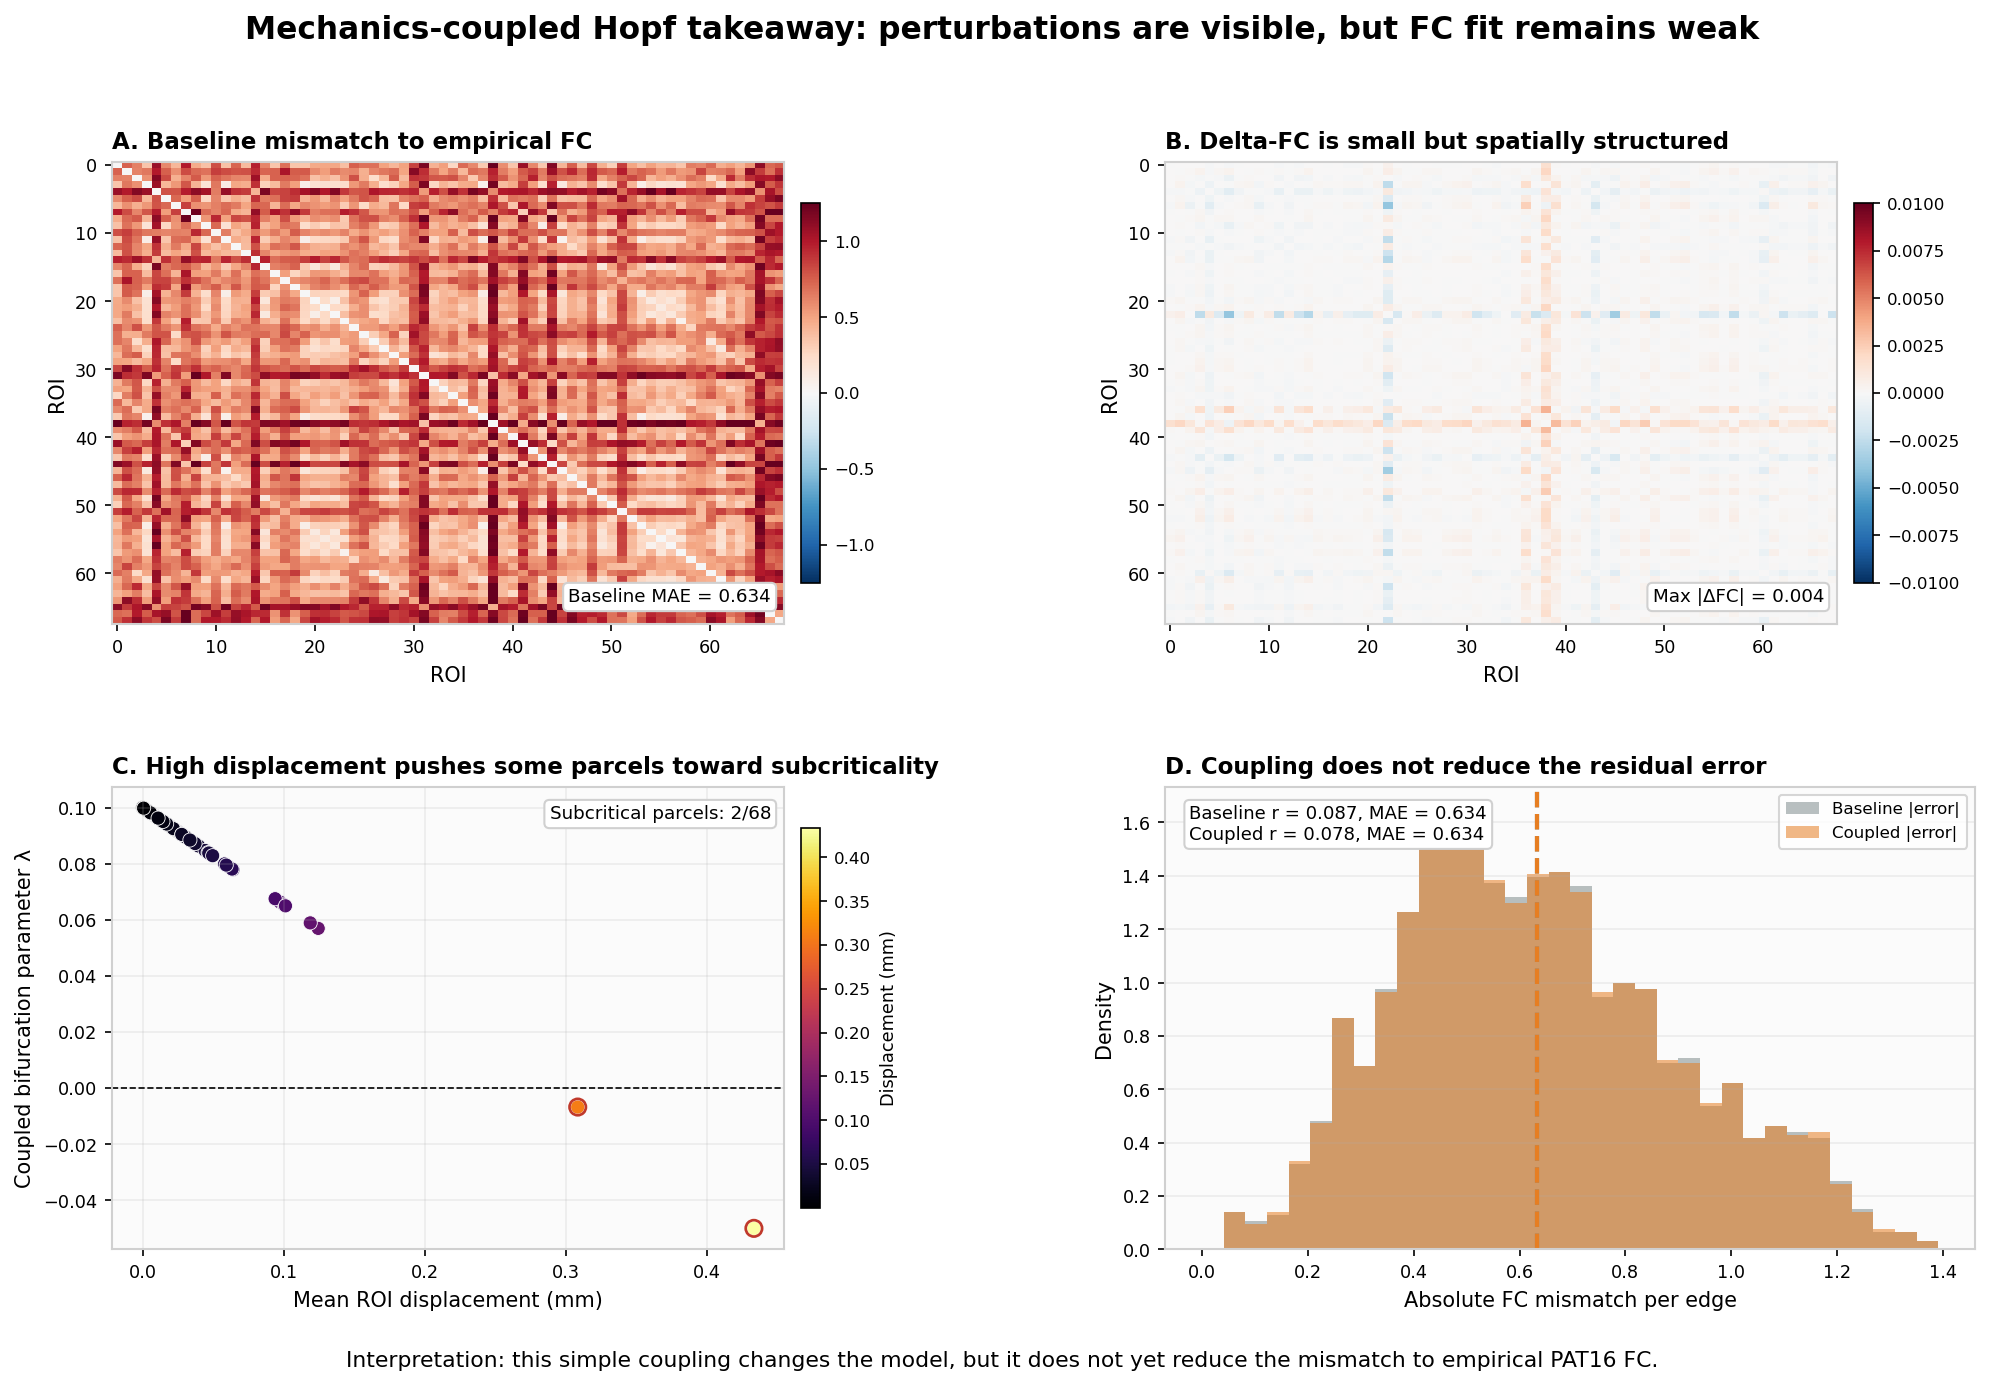

Saved figure: figures/capstone/figC07_02_coupled_dynamics_takeaway.png
Saved figure: figures/capstone/figC07_02_coupled_dynamics_takeaway.pdf

FC correlation with empirical:
  Baseline:  r = 0.087
  Coupled:   r = 0.078
  Baseline MAE: 0.634
  Coupled MAE:  0.634


In [11]:
# Coupled simulation
z_coupled = z0.copy()
activity_coupled = np.zeros_like(activity)
for step in range(N_steps):
    activity_coupled[:, step] = np.abs(z_coupled)
    z_coupled = hopf_dynamics(z_coupled, SC_coupled, J=0.05,
                              lambda_vals=lambda_coupled, dt=dt)
FC_coupled = np.corrcoef(activity_coupled)

r_coupled = np.corrcoef(FC_coupled[triu], FC_empirical[triu])[0, 1]
dfc = FC_coupled - FC_simulated_pre
vmax_d = max(np.abs(dfc).max(), 0.01)

err_baseline = FC_simulated_pre - FC_empirical
err_coupled = FC_coupled - FC_empirical
err_edges_baseline = err_baseline[triu]
err_edges_coupled = err_coupled[triu]
abs_err_baseline = np.abs(err_edges_baseline)
abs_err_coupled = np.abs(err_edges_coupled)
mae_baseline = abs_err_baseline.mean()
mae_coupled = abs_err_coupled.mean()
vmax_err = np.nanpercentile(np.abs(np.concatenate([err_edges_baseline, err_edges_coupled])), 99)
vmax_err = max(vmax_err, 0.2)

fig, axes = plt.subplots(2, 2, figsize=(13.8, 9.8), constrained_layout=False)
fig.subplots_adjust(top=0.87, bottom=0.13, left=0.07, right=0.97, wspace=0.30, hspace=0.35)

for ax in axes.ravel():
    ax.set_facecolor('#fbfbfb')
    for spine in ax.spines.values():
        spine.set_color('#d0d0d0')
        spine.set_linewidth(1.0)
    ax.tick_params(labelsize=8.5)

# Panel A: where the baseline model disagrees with empirical FC.
ax = axes[0, 0]
im = ax.imshow(err_baseline, cmap='RdBu_r', vmin=-vmax_err, vmax=vmax_err, aspect='auto')
ax.set_title('A. Baseline mismatch to empirical FC', loc='left', fontweight='bold', fontsize=11)
ax.set_xlabel('ROI')
ax.set_ylabel('ROI')
cbar = fig.colorbar(im, ax=ax, shrink=0.82, pad=0.02)
cbar.ax.tick_params(labelsize=8)
ax.text(
    0.98,
    0.04,
    f'Baseline MAE = {mae_baseline:.3f}',
    transform=ax.transAxes,
    ha='right',
    va='bottom',
    fontsize=8.8,
    bbox=dict(boxstyle='round,pad=0.28', fc='white', ec='#d0d0d0'),
)

# Panel B: delta-FC highlights where coupling changes the model.
ax = axes[0, 1]
im = ax.imshow(dfc, cmap='RdBu_r', vmin=-vmax_d, vmax=vmax_d, aspect='auto')
ax.set_title('B. Delta-FC is small but spatially structured', loc='left', fontweight='bold', fontsize=11)
ax.set_xlabel('ROI')
ax.set_ylabel('ROI')
cbar = fig.colorbar(im, ax=ax, shrink=0.82, pad=0.02)
cbar.ax.tick_params(labelsize=8)
ax.text(
    0.98,
    0.04,
    f'Max |ΔFC| = {np.abs(dfc).max():.3f}',
    transform=ax.transAxes,
    ha='right',
    va='bottom',
    fontsize=8.8,
    bbox=dict(boxstyle='round,pad=0.28', fc='white', ec='#d0d0d0'),
)

# Panel C: mechanics drives lambda downward in highly displaced parcels.
ax = axes[1, 0]
sc = ax.scatter(roi_disp, lambda_coupled, c=roi_disp, cmap='inferno', s=46, edgecolor='white', linewidth=0.4)
ax.axhline(0, color='k', lw=0.8, ls='--')
subcritical = lambda_coupled < 0
if np.any(subcritical):
    ax.scatter(roi_disp[subcritical], lambda_coupled[subcritical], s=62, facecolor='none', edgecolor='#c0392b', linewidth=1.3)
ax.set_xlabel('Mean ROI displacement (mm)')
ax.set_ylabel('Coupled bifurcation parameter λ')
ax.set_title('C. High displacement pushes some parcels toward subcriticality', loc='left', fontweight='bold', fontsize=11)
ax.grid(alpha=0.20)
cbar = fig.colorbar(sc, ax=ax, shrink=0.82, pad=0.02)
cbar.set_label('Displacement (mm)', fontsize=8.5)
cbar.ax.tick_params(labelsize=8)
ax.text(
    0.98,
    0.96,
    f'Subcritical parcels: {(lambda_coupled < 0).sum()}/{N_REGIONS}',
    transform=ax.transAxes,
    ha='right',
    va='top',
    fontsize=8.8,
    bbox=dict(boxstyle='round,pad=0.28', fc='white', ec='#d0d0d0'),
)

# Panel D: did coupling reduce the mismatch?
ax = axes[1, 1]
bins = np.linspace(0, max(abs_err_baseline.max(), abs_err_coupled.max()), 35)
ax.hist(abs_err_baseline, bins=bins, density=True, alpha=0.55, color='#7f8c8d', label='Baseline |error|')
ax.hist(abs_err_coupled, bins=bins, density=True, alpha=0.55, color='#e67e22', label='Coupled |error|')
ax.axvline(mae_baseline, color='#7f8c8d', lw=2, ls='--')
ax.axvline(mae_coupled, color='#e67e22', lw=2, ls='--')
ax.set_xlabel('Absolute FC mismatch per edge')
ax.set_ylabel('Density')
ax.set_title('D. Coupling does not reduce the residual error', loc='left', fontweight='bold', fontsize=11)
ax.grid(alpha=0.20, axis='y')
ax.legend(frameon=True, fontsize=8, loc='upper right')
ax.text(
    0.03,
    0.96,
    f'Baseline r = {r_sim_emp:.3f}, MAE = {mae_baseline:.3f}\nCoupled r = {r_coupled:.3f}, MAE = {mae_coupled:.3f}',
    transform=ax.transAxes,
    ha='left',
    va='top',
    fontsize=8.7,
    bbox=dict(boxstyle='round,pad=0.28', fc='white', ec='#d0d0d0'),
)

fig.suptitle('Mechanics-coupled Hopf takeaway: perturbations are visible, but FC fit remains weak', fontsize=15, fontweight='bold', y=0.97)
fig.text(
    0.5,
    0.05,
    'Interpretation: this simple coupling changes the model, but it does not yet reduce the mismatch to empirical PAT16 FC.',
    ha='center',
    fontsize=10.5,
)

out_path_png = FIG_DIR / 'figC07_02_coupled_dynamics_takeaway.png'
out_path_pdf = FIG_DIR / 'figC07_02_coupled_dynamics_takeaway.pdf'
fig.savefig(out_path_png, bbox_inches='tight')
fig.savefig(out_path_pdf, bbox_inches='tight')
plt.show()

print(f'Saved figure: {out_path_png}')
print(f'Saved figure: {out_path_pdf}')
print(f'\nFC correlation with empirical:')
print(f'  Baseline:  r = {r_sim_emp:.3f}')
print(f'  Coupled:   r = {r_coupled:.3f}')
print(f'  Baseline MAE: {mae_baseline:.3f}')
print(f'  Coupled MAE:  {mae_coupled:.3f}')

## Notes for the mechanics-coupled Hopf figure

This figure is designed to answer the next question: **what does the current mechanics coupling actually change, and does that change reduce the mismatch to empirical FC?**

### Panel A. Baseline mismatch to empirical FC

**What is shown:** the residual matrix `FC_baseline - FC_empirical`.

**Why it matters:** this makes the baseline failure explicit instead of showing only the raw simulated FC.

**Interpretation:** the baseline model differs from empirical FC in a structured way, not just by random noise. This provides the reference mismatch that the coupled model should ideally reduce.

### Panel B. Delta-FC is small but spatially structured

**What is shown:** the difference matrix `FC_coupled - FC_baseline`.

**Why it matters:** this isolates the effect of coupling itself.

**Interpretation:** the changes are structured rather than random, but their magnitude remains small. The coupling is active, yet its effect on FC is limited under the current parameter choice.

### Panel C. High displacement pushes some parcels toward subcriticality

**What is shown:** parcel displacement versus the coupled bifurcation parameter `λ`.

**Why it matters:** this makes the coupling rule explicit at the parcel level.

**Interpretation:** more displaced parcels are pushed downward in `λ`, and some cross into the subcritical regime. This confirms that the mechanics-informed perturbation is mechanistically active inside the model, even if the FC fit remains weak.

### Panel D. Coupling does not reduce the residual error

**What is shown:** the distribution of absolute FC residuals for the baseline and coupled models, together with their correlation and mean absolute error summaries.

**Why it matters:** this is the clearest answer to the practical modeling question: did coupling help?

**Interpretation:** in the current setup, the answer is essentially **no**. The coupled model changes the dynamics, but it does not reduce the overall FC mismatch to empirical PAT16 data.

### Slide takeaway

The current mechanics coupling is **mechanistically visible but not yet sufficient**. It changes the dynamical parameters and produces a measurable `ΔFC`, but it does not reduce the residual mismatch to empirical PAT16 FC. This is the key motivation for the inverse problem and parameter-identification steps that follow in later work.

---
## Summary

In this notebook we have:

- Reviewed neural mass models and the Hopf bifurcation
- Simulated baseline neural dynamics on the pre-op connectome
- Implemented the mechanics-dynamics coupling via SC modulation and bifurcation shift
- Compared baseline and coupled FC with empirical FC

### Limitations

The current uniform $\lambda = 0.1$ produces similar FC regardless of SC.
The **inverse problem** -- fitting $\lambda_i$ and $J$ to empirical FC --
is required for meaningful differentiation between baseline and coupled
models. This is a key mathematical challenge (NB\_C09).

---

## References

- Deco G et al. (2017). The dynamics of resting fluctuations in the brain. *Nat Rev Neurosci* 18(6):349--364.
- Smith DH et al. (1999). High tolerance and delayed elastic response of cultured axons to dynamic stretch injury. *J Neurosci* 19(11):4263--4269.

---

**Next:** [NB\_C08](NB_C08_Closing_the_Loop.ipynb) -- Predicted vs observed cognitive change